# Logistic Regression — Baseline Model

## 1. Objective

The objective of this notebook is to build a baseline Logistic Regression classifier to predict the class of a vehicle using its numerical features.

The target variable, `vehicle_class`, contains three classes:

- `0`: Sedan
- `1`: SUV
- `2`: Sports Car

We will use the cleaned training dataset prepared in Notebook 2 and follow the shared training-validation split to ensure a fair comparison with other models developed for the project.

We will first train a baseline model, evaluate its performance on the validation set, and document our observations before attempting any improvements.

## 2. Import libraries and configure the data path

We import the libraries required to load the dataset, prepare the features and target variable, split the data using the shared split assignments, train Logistic Regression, and evaluate the model.

The data directory points to the shared project data folder in Google Drive. We will reuse the cleaned dataset and saved split rather than independently creating a new split.## 2. Import libraries and configure the data path

We import the libraries required to load the dataset, prepare the features and target variable, split the data using the shared split assignments, train Logistic Regression, and evaluate the model.

The data directory points to the shared project data folder in Google Drive. We will reuse the cleaned dataset and saved split rather than independently creating a new split.

In [ ]:
# Import the Google Colab Drive integration
from google.colab import drive

# Mount Google Drive so the notebook can access project files
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Path handling for locating files in Google Drive
from pathlib import Path

# Data manipulation and numerical operations
import numpy as np
import pandas as pd

# Pipeline combines preprocessing and model training
from sklearn.pipeline import Pipeline

# Standardizes numerical features
from sklearn.preprocessing import StandardScaler

# Classification algorithm
from sklearn.linear_model import LogisticRegression

# Metrics for evaluating the classification model
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# Plotting library for visualizing the confusion matrix
import matplotlib.pyplot as plt

# Folder containing the cleaned dataset and shared split file
DATA_DIR = Path("/content/drive/MyDrive/MLproject/data")

# Display the configured directory
print("Data directory:", DATA_DIR)

Data directory: /content/drive/MyDrive/MLproject/data


## 3. Load the prepared data

We load the cleaned training dataset and the split assignment file created in Notebook 2.

The split file identifies which rows belong to the training subset and which belong to the validation subset. Using these saved assignments allows our experiments and Girish's Decision Tree experiments to use the same observations for training and validation.

We exclude `vehicle_id` from the predictors because it is an identifier rather than a vehicle measurement. The target variable is `vehicle_class`.

In [ ]:
# Load the cleaned training dataset created in Notebook 2
train_clean = pd.read_csv(DATA_DIR / "vehicle_train_clean.csv")

# Load the saved training-validation assignments
split_indices = pd.read_csv(DATA_DIR / "vehicle_split_indices.csv")

# Define the identifier and target column names
ID_COLUMN = "vehicle_id"
TARGET_COLUMN = "vehicle_class"

# Select all predictor columns, excluding the ID and target
FEATURE_COLUMNS = [
    col for col in train_clean.columns
    if col not in [ID_COLUMN, TARGET_COLUMN]
]

# Create X containing the 20 numerical predictor features
X = train_clean[FEATURE_COLUMNS].copy()

# Create y containing the target class labels
y = train_clean[TARGET_COLUMN].copy()

# Use the original row indices recorded in the split file
split_indices = split_indices.set_index("row_index")

# Identify the rows assigned to the training subset
train_rows = split_indices.index[
    split_indices["split"].eq("train")
]

# Identify the rows assigned to the validation subset
val_rows = split_indices.index[
    split_indices["split"].eq("validation")
]

# Construct the training feature matrix and target vector
X_train = X.loc[train_rows]
y_train = y.loc[train_rows]

# Construct the validation feature matrix and target vector
X_val = X.loc[val_rows]
y_val = y.loc[val_rows]

# Display the dimensions of the resulting datasets
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Training targets:", y_train.shape)
print("Validation targets:", y_val.shape)

# Check whether class proportions are similar across the two subsets
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nValidation class proportions:")
print(y_val.value_counts(normalize=True).sort_index().round(3))

Training features: (6000, 20)
Validation features: (1500, 20)
Training targets: (6000,)
Validation targets: (1500,)

Training class proportions:
vehicle_class
0    0.338
1    0.332
2    0.330
Name: proportion, dtype: float64

Validation class proportions:
vehicle_class
0    0.339
1    0.332
2    0.329
Name: proportion, dtype: float64


## 4. Train the baseline model

Logistic Regression is a classification algorithm that estimates the probabilities of an observation belonging to each class.

Our dataset contains numerical features measured on different scales. For example, vehicle weight is measured in kilograms, while the drag coefficient is much smaller. We therefore use `StandardScaler` to standardize the features.

We place the scaler and Logistic Regression model inside a `Pipeline`. The scaler learns its parameters only from the training subset, preventing information from the validation subset from leaking into preprocessing.

We start with a straightforward baseline using the default L2 regularization and `C=1.0`. We will not tune the model yet.

In [ ]:
# Build a pipeline that standardizes features before classification
baseline_model = Pipeline([

    # Learn feature means and standard deviations from training data only
    ("scaler", StandardScaler()),

    # Create the baseline Logistic Regression classifier
    # C=1.0 is the initial regularization setting
    # max_iter=2000 allows sufficient iterations for convergence
    # random_state=42 makes supported randomized behavior reproducible
    ("logistic_regression", LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

# Fit the complete pipeline using only the training subset
baseline_model.fit(X_train, y_train)

# Confirm that training completed
print("Baseline Logistic Regression trained successfully.")

Baseline Logistic Regression trained successfully.


## 5. Evaluate the baseline model

After training, we use the model to predict vehicle classes for the unseen validation data.

We evaluate the model using:

- **Accuracy:** The proportion of validation observations classified correctly.
- **Macro F1-score:** The average F1-score across all three classes, giving each class equal importance.
- **Classification report:** Shows precision, recall, F1-score, and support for each class.

The validation set is not used to train the model. It helps us estimate how well the baseline generalizes to unseen observations.

In [ ]:
# Predict vehicle classes for the validation dataset
y_val_pred = baseline_model.predict(X_val)

# Calculate the overall proportion of correct predictions
baseline_accuracy = accuracy_score(y_val, y_val_pred)

# Calculate F1-score independently for each class, then average equally
baseline_macro_f1 = f1_score(
    y_val,
    y_val_pred,
    average="macro"
)

# Display the overall evaluation metrics
print("BASELINE LOGISTIC REGRESSION RESULTS")
print("------------------------------------")
print(f"Validation Accuracy: {baseline_accuracy:.4f}")
print(f"Validation Macro F1-score: {baseline_macro_f1:.4f}")

# Display precision, recall, F1-score, and sample count for each class
print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred,
        labels=[0, 1, 2],
        target_names=["Sedan", "SUV", "Sports Car"],
        zero_division=0
    )
)

BASELINE LOGISTIC REGRESSION RESULTS
------------------------------------
Validation Accuracy: 0.8840
Validation Macro F1-score: 0.8844

Classification Report:
              precision    recall  f1-score   support

       Sedan       0.83      0.83      0.83       508
         SUV       0.90      0.89      0.90       498
  Sports Car       0.92      0.93      0.92       494

    accuracy                           0.88      1500
   macro avg       0.88      0.88      0.88      1500
weighted avg       0.88      0.88      0.88      1500



### Baseline observations

The baseline Logistic Regression model achieved a validation accuracy of **88.40%** and a macro F1-score of **88.44%**.

Sports Car had the highest class-level F1-score (0.92), followed by SUV (0.90) and Sedan (0.83). Sedan was the most challenging class for the model to classify.

The similar accuracy and macro F1-score are consistent with the approximately balanced class distribution. These results provide a reference point for evaluating future experiments.

No hyperparameter tuning has been performed yet. We will retain these baseline results when comparing subsequent configurations.

## 6. Confusion Matrix Analysis

### What are we doing?

In this section, we analyze the predictions made by our baseline Logistic Regression model using a confusion matrix. Although accuracy tells us the overall percentage of correct predictions, it does not tell us which vehicle classes the model confuses with one another.

### Why are we doing this?

Our dataset contains three classes: Sedan (0), SUV (1), and Sports Car (2). The classification report showed that Sedan had a lower F1-score (0.83) than SUV (0.90) and Sports Car (0.92). We want to investigate the types of classification errors that may explain this difference.

### How does a confusion matrix work?

A confusion matrix compares the actual class labels with the predicted class labels.

- **Rows represent actual classes.**
- **Columns represent predicted classes.**
- **Diagonal entries represent correct predictions.**
- **Off-diagonal entries represent incorrect predictions.**

For example, the cell at the intersection of the actual Sedan row and predicted SUV column indicates how many actual Sedans were incorrectly classified as SUVs.

### What will we learn?

The confusion matrix will help us identify the most frequent class confusions and understand where our baseline model performs well or poorly. We will use these observations to guide subsequent experiments rather than changing model parameters without evidence.

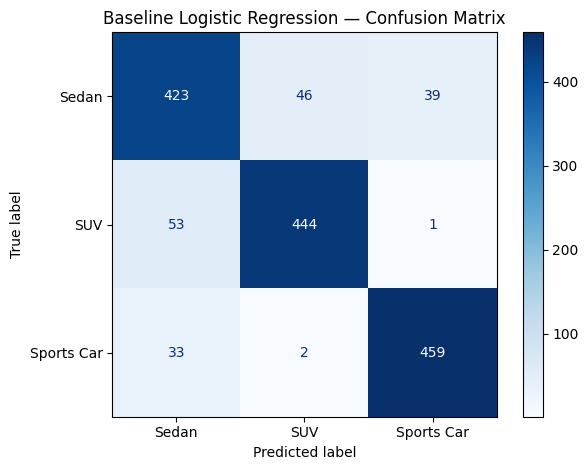

In [ ]:
# Calculate the confusion matrix using actual and predicted labels.
# The order of labels is fixed so the matrix follows:
# 0 = Sedan, 1 = SUV, 2 = Sports Car.
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[0, 1, 2]
)

# Create a display object with readable vehicle class names.
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Sedan", "SUV", "Sports Car"]
)
# Plot the matrix.
# Darker cells indicate larger counts, and the numbers show
# the exact number of observations in each actual-predicted pair.
cm_display.plot(cmap="Blues", values_format="d")
plt.title("Baseline Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()



### Observations from the Confusion Matrix

The confusion matrix shows that the baseline Logistic Regression model correctly classified 423 Sedans, 444 SUVs, and 459 Sports Cars.

**Sedan was the most challenging class.** Of the 508 actual Sedans, 46 were incorrectly classified as SUVs and 39 as Sports Cars. Similarly, 53 actual SUVs and 33 actual Sports Cars were classified as Sedans.

The model distinguished SUVs and Sports Cars effectively, with only one SUV classified as a Sports Car and two Sports Cars classified as SUVs.

These results suggest that Sedan is less clearly separated from the other classes by the current Logistic Regression model. The confusion matrix helps identify these error patterns but does not establish their underlying causes.

We will retain these baseline results and next investigate how the model performs when random measurement noise is added to a copy of the validation features. This will help us assess the model's robustness to imperfect measurements.

## 7. Robustness Evaluation Using Noisy Validation Data

### 7.1 Objective

The Kaggle competition description states that the hidden evaluation data may contain additional random measurement errors because the final samples are collected under a different measurement environment.

Our baseline Logistic Regression model achieved 88.40% accuracy on clean validation data. We now want to investigate how its performance changes when the input measurements become less precise.

### 7.2 Experimental methodology

We will create noisy copies of the validation feature matrix and evaluate our already-trained baseline model on them.

We will consider three noise levels:

- **0.0:** No added noise; the clean-data reference.
- **0.1:** Gaussian noise with a standard deviation equal to 10% of each feature's standard deviation in the training data.
- **0.2:** Gaussian noise with a standard deviation equal to 20% of each feature's standard deviation in the training data.

The noise will be generated independently for each feature value. We will use the original validation labels to calculate accuracy and macro F1-score.

### 7.3 Why is this experiment useful?

This experiment helps us understand whether the baseline model is sensitive to simulated measurement errors. A decline in performance as noise increases would indicate that the model is less robust to the tested perturbations.

We will use the same trained model for all three conditions, so we can isolate the effect of changing the input measurements.

### 7.4 Limitations

The competition description confirms that the hidden evaluation data may contain additional measurement noise, but it does not specify the exact noise distribution or magnitude.

Therefore, the noise levels used here are experimental settings, not confirmed reproductions of the hidden test-generation process. The resulting scores measure simulated robustness and do not establish our actual Kaggle test accuracy.

In [ ]:
# Import NumPy for generating reproducible random noise.
import numpy as np

# Create a random number generator with a fixed seed.
# This allows the same noise experiment to be reproduced.
rng = np.random.default_rng(42)

# Calculate each feature's standard deviation from the training subset.
# We use training statistics to determine the scale of the noise.
feature_std = X_train.std(axis=0, ddof=0)

# Define the noise levels to investigate.
noise_levels = [0.0, 0.1, 0.2]

# Store the evaluation results for each noise level.
noisy_results = []

# Evaluate the same trained baseline model at each noise level.
for noise_level in noise_levels:

    # Create a copy of the validation features.
    # The original X_val remains unchanged.
    X_val_noisy = X_val.copy()

    # Generate independent Gaussian noise for each feature value.
    # The noise standard deviation is proportional to that feature's
    # standard deviation in the training subset.
    noise = rng.normal(
        loc=0.0,
        scale=noise_level * feature_std.to_numpy(),
        size=X_val.shape
    )

    # Add noise only to the copied validation feature matrix.
    X_val_noisy.iloc[:, :] = X_val.to_numpy() + noise

    # Generate predictions using the already-trained baseline pipeline.
    # No fitting or retraining occurs in this step.
    y_noisy_pred = baseline_model.predict(X_val_noisy)

    # Calculate classification accuracy using the original validation labels.
    noisy_accuracy = accuracy_score(y_val, y_noisy_pred)

    # Calculate macro F1-score, giving each class equal weight.
    noisy_macro_f1 = f1_score(
        y_val,
        y_noisy_pred,
        average="macro"
    )

    # Save the results for this noise level.
    noisy_results.append({
        "Noise Level": noise_level,
        "Accuracy": noisy_accuracy,
        "Macro F1": noisy_macro_f1
    })

# Convert the results into a DataFrame.
noisy_results_df = pd.DataFrame(noisy_results)

# Display the scores for comparison.
print("BASELINE PERFORMANCE UNDER DIFFERENT NOISE LEVELS")
print("-------------------------------------------------")
print(noisy_results_df.round(4).to_string(index=False))

BASELINE PERFORMANCE UNDER DIFFERENT NOISE LEVELS
-------------------------------------------------
 Noise Level  Accuracy  Macro F1
         0.0    0.8840    0.8844
         0.1    0.8813    0.8817
         0.2    0.8760    0.8764


### Observations from Noisy Validation

The baseline Logistic Regression model achieved 88.40% accuracy and a macro F1-score of 88.44% on clean validation data.

At noise level 0.1, accuracy decreased to 88.13%, while macro F1 decreased to 88.17%. At noise level 0.2, accuracy decreased to 87.60% and macro F1 to 87.64%.

The gradual decline in both metrics indicates that the model is somewhat sensitive to the simulated measurement noise, although the overall performance reduction was relatively small for the tested noise levels.

These findings suggest reasonable robustness under the simulated Gaussian perturbations. However, the experiment does not establish the model's performance on the hidden Kaggle test data because the actual test-noise distribution and magnitude are unspecified.

## 8. Stratified 5-Fold Cross-Validation

### Objective

The baseline Logistic Regression model achieved 88.40% accuracy on the clean validation set. However, this score comes from a single training-validation split.

We will use 5-fold stratified cross-validation to evaluate the model across five different training and evaluation folds.

### Methodology

The 6,000-row training subset is divided into five approximately equal folds. In each iteration, four folds are used to train the model and the remaining fold is used to evaluate it. Each fold serves as the evaluation fold once.

Stratification helps preserve the proportions of Sedan, SUV, and Sports Car observations across folds.

### Evaluation metrics

We will record accuracy and macro F1-score for every fold, then calculate their means and standard deviations.

The mean summarizes average performance across folds, while the standard deviation indicates how much the scores vary.

### Experimental design

Cross-validation will be performed only on the 6,000-row training subset. Our separate 1,500-row validation set will remain outside cross-validation and will not be used to fit the models during this experiment.

Cross-validation does not directly increase accuracy. Instead, it helps us evaluate performance more reliably and select hyperparameters for subsequent experiments.

In [ ]:
# Import the tools needed for stratified cross-validation.
from sklearn.model_selection import StratifiedKFold, cross_validate

# Create five stratified folds.
# Shuffling randomizes the observations before dividing them into folds.
# A fixed random state makes the fold assignments reproducible.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the baseline pipeline using only the training subset.
# The pipeline fits StandardScaler separately within each training fold,
# preventing information from each evaluation fold from leaking into scaling.
cv_results = cross_validate(
    estimator=baseline_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro"
    },
    return_train_score=False,
    n_jobs=-1
)

# Store the accuracy and macro F1-score for each fold.
cv_scores = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Macro F1": cv_results["test_macro_f1"]
})

# Print the fold-by-fold results.
# Using to_string avoids the earlier variable-name conflict with display().
print("CROSS-VALIDATION SCORES BY FOLD")
print("--------------------------------")
print(cv_scores.round(4).to_string(index=False))

# Calculate the mean and sample standard deviation across folds.
mean_accuracy = cv_scores["Accuracy"].mean()
std_accuracy = cv_scores["Accuracy"].std()

mean_macro_f1 = cv_scores["Macro F1"].mean()
std_macro_f1 = cv_scores["Macro F1"].std()

# Display the summary statistics.
print("\nCROSS-VALIDATION SUMMARY")
print("------------------------")
print(f"Mean accuracy: {mean_accuracy:.4f}")
print(f"Accuracy standard deviation: {std_accuracy:.4f}")
print(f"Mean macro F1-score: {mean_macro_f1:.4f}")
print(f"Macro F1 standard deviation: {std_macro_f1:.4f}")

CROSS-VALIDATION SCORES BY FOLD
--------------------------------
 Fold  Accuracy  Macro F1
    1    0.9025    0.9029
    2    0.8900    0.8904
    3    0.8875    0.8880
    4    0.9025    0.9025
    5    0.8950    0.8956

CROSS-VALIDATION SUMMARY
------------------------
Mean accuracy: 0.8955
Accuracy standard deviation: 0.0069
Mean macro F1-score: 0.8959
Macro F1 standard deviation: 0.0068


### Observations from 5-Fold Cross-Validation

The baseline Logistic Regression model achieved a mean cross-validation accuracy of **89.55%** and a mean macro F1-score of **89.59%** across five stratified folds.

The accuracy standard deviation was 0.0069, while the macro F1 standard deviation was 0.0068. The fold accuracies ranged from 88.75% to 90.25%, indicating relatively consistent performance across the different training-validation splits.

The mean cross-validation accuracy was higher than the 88.40% accuracy obtained on the original held-out validation set. This difference may arise from variation in the samples used for training and evaluation. Both results are retained for a more complete assessment of the baseline model.

Overall, cross-validation suggests that the baseline Logistic Regression model has reasonably stable performance on the cleaned training data. However, its performance on the hidden Kaggle test set remains unknown until a submission is evaluated.

### Hyperparameter Tuning for Logistic Regression

The baseline Logistic Regression model uses `C = 1.0` and achieved a mean five-fold cross-validation accuracy of 89.55%.

We will investigate different values of `C` to determine how regularization strength affects model performance. We will use stratified five-fold cross-validation on the clean training subset, with feature scaling performed inside the pipeline to avoid data leakage.

After identifying promising candidates, we will compare their performance on clean and simulated noisy validation data. This will help us determine whether a candidate offers a useful balance between predictive accuracy and robustness to measurement noise.

In [ ]:
# Tune Logistic Regression regularization using 5-fold CV.

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Keep preprocessing inside the pipeline to avoid data leakage.
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

# Smaller C means stronger regularization.
param_grid = {
    "logistic_regression__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
}

# Use identical, reproducible stratified folds for all candidates.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro"
    },
    refit="macro_f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

grid_search.fit(X_train, y_train)

# Display results for every C value.
tuning_results = pd.DataFrame(grid_search.cv_results_)

tuning_summary = pd.DataFrame({
    "C": tuning_results["param_logistic_regression__C"].astype(float),
    "Mean CV Accuracy": tuning_results["mean_test_accuracy"],
    "Mean CV Macro F1": tuning_results["mean_test_macro_f1"],
    "Accuracy Std": tuning_results["std_test_accuracy"],
    "Macro F1 Std": tuning_results["std_test_macro_f1"]
})

print("LOGISTIC REGRESSION HYPERPARAMETER TUNING")
print("-----------------------------------------")
print(tuning_summary.round(4).to_string(index=False))

print("\nBest C based on mean CV Macro F1:",
      grid_search.best_params_["logistic_regression__C"])

print("Best mean CV Macro F1:",
      round(grid_search.best_score_, 4))

LOGISTIC REGRESSION HYPERPARAMETER TUNING
-----------------------------------------
      C  Mean CV Accuracy  Mean CV Macro F1  Accuracy Std  Macro F1 Std
  0.001            0.8677            0.8677        0.0094        0.0092
  0.010            0.8905            0.8908        0.0065        0.0063
  0.100            0.8965            0.8969        0.0064        0.0063
  1.000            0.8955            0.8959        0.0062        0.0061
 10.000            0.8945            0.8949        0.0066        0.0064
100.000            0.8945            0.8949        0.0064        0.0062

Best C based on mean CV Macro F1: 0.1
Best mean CV Macro F1: 0.8969


### Comparing Baseline and Tuned Logistic Regression Under Measurement Noise

Cross-validation identified `C = 0.1` as the best regularization setting among the tested candidates, based on mean macro F1.

We will now compare the original baseline (`C = 1.0`) with the tuned model (`C = 0.1`) on the same held-out validation examples. To assess robustness, we will evaluate both models on clean validation data and on copies with simulated Gaussian measurement noise at levels 0.1 and 0.2.

Using the same noise realizations for both models ensures that the comparison is not affected by different random perturbations. The validation labels remain unchanged because the experiment assumes that measurement noise affects the features, not the underlying class.

In [ ]:
# Compare baseline and tuned Logistic Regression models.
# Both models use the same training data and validation examples.

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Baseline model: C = 1.0
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        C=1.0,
        max_iter=3000,
        random_state=42
    ))
])

# Tuned model: C = 0.1
tuned_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        C=0.1,
        max_iter=3000,
        random_state=42
    ))
])

# Fit both models on the same clean training data.
baseline_model.fit(X_train, y_train)
tuned_model.fit(X_train, y_train)

# Generate each noisy validation copy only once,
# so both models receive identical perturbations.
rng = np.random.default_rng(42)
noise_levels = [0.0, 0.1, 0.2]
noise_data = {}

feature_std = X_train.std(axis=0)

for noise_level in noise_levels:
    if noise_level == 0.0:
        X_noisy = X_val.copy()
    else:
        noise = rng.normal(
            loc=0.0,
            scale=noise_level * feature_std.to_numpy(),
            size=X_val.shape
        )
        X_noisy = X_val + noise

    noise_data[noise_level] = X_noisy

# Evaluate both models under each noise condition.
results = []

for model_name, model in [
    ("Baseline C=1.0", baseline_model),
    ("Tuned C=0.1", tuned_model)
]:
    for noise_level, X_eval in noise_data.items():
        predictions = model.predict(X_eval)

        results.append({
            "Model": model_name,
            "Noise Level": noise_level,
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro F1": f1_score(
                y_val, predictions, average="macro"
            )
        })

comparison_df = pd.DataFrame(results)

print("CLEAN AND NOISY VALIDATION COMPARISON")
print("------------------------------------")
print(comparison_df.round(4).to_string(index=False))

CLEAN AND NOISY VALIDATION COMPARISON
------------------------------------
         Model  Noise Level  Accuracy  Macro F1
Baseline C=1.0          0.0    0.8840    0.8844
Baseline C=1.0          0.1    0.8807    0.8811
Baseline C=1.0          0.2    0.8727    0.8731
   Tuned C=0.1          0.0    0.8827    0.8831
   Tuned C=0.1          0.1    0.8807    0.8811
   Tuned C=0.1          0.2    0.8793    0.8797


### Exploring Nonlinear Decision Boundaries with Polynomial Features

The current Logistic Regression model achieves approximately 89.6% mean cross-validation accuracy. Its confusion matrix indicates that Sedan is frequently confused with the other vehicle classes.

Standard Logistic Regression learns linear decision boundaries in the original feature space. To investigate whether nonlinear relationships can improve classification, we will generate degree-2 polynomial features, including squared features and pairwise interactions.

We will tune the regularization parameter using stratified five-fold cross-validation on the clean training subset. Polynomial feature generation and scaling will be performed inside the pipeline to prevent information leakage between folds.

We will then compare the results with the original Logistic Regression model and evaluate the promising candidate on clean and simulated noisy validation data.

In [ ]:
# Experiment: Degree-2 Polynomial Logistic Regression
# All transformations are fitted within each CV training fold.

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

poly_pipeline = Pipeline([
    ("polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

# Degree 2 adds squared features and pairwise interactions.
# Tune regularization to control the larger feature space.
poly_param_grid = {
    "logistic_regression__C": [0.001, 0.01, 0.1, 1.0, 10.0]
}

poly_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

poly_search = GridSearchCV(
    estimator=poly_pipeline,
    param_grid=poly_param_grid,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro"
    },
    refit="macro_f1",
    cv=poly_cv,
    n_jobs=-1,
    return_train_score=False
)

poly_search.fit(X_train, y_train)

poly_results = pd.DataFrame(poly_search.cv_results_)

poly_summary = pd.DataFrame({
    "C": poly_results["param_logistic_regression__C"].astype(float),
    "Mean CV Accuracy": poly_results["mean_test_accuracy"],
    "Mean CV Macro F1": poly_results["mean_test_macro_f1"],
    "Accuracy Std": poly_results["std_test_accuracy"],
    "Macro F1 Std": poly_results["std_test_macro_f1"]
})

print("POLYNOMIAL LOGISTIC REGRESSION RESULTS")
print("--------------------------------------")
print(poly_summary.round(4).to_string(index=False))

print("\nBest C:",
      poly_search.best_params_["logistic_regression__C"])
print("Best mean CV accuracy:",
      round(poly_results.loc[
          poly_search.best_index_, "mean_test_accuracy"
      ], 4))
print("Best mean CV macro F1:",
      round(poly_search.best_score_, 4))

POLYNOMIAL LOGISTIC REGRESSION RESULTS
--------------------------------------
     C  Mean CV Accuracy  Mean CV Macro F1  Accuracy Std  Macro F1 Std
 0.001            0.8903            0.8907        0.0087        0.0085
 0.010            0.8950            0.8954        0.0062        0.0062
 0.100            0.8950            0.8954        0.0051        0.0050
 1.000            0.8923            0.8927        0.0073        0.0071
10.000            0.8890            0.8894        0.0055        0.0052

Best C: 0.1
Best mean CV accuracy: 0.895
Best mean CV macro F1: 0.8954


### Conclusion: Polynomial Logistic Regression

Polynomial Logistic Regression was evaluated using degree-2 polynomial features and five-fold cross-validation. The best result was obtained with `C = 0.1`, achieving a mean accuracy of 89.50% and a mean macro F1-score of 89.54%.

These results did not improve upon standard Logistic Regression, which achieved 89.65% mean cross-validation accuracy and 89.69% mean macro F1-score. Therefore, we will retain standard Logistic Regression as our preferred Logistic Regression variant and investigate other approaches for further improvement.

### Comparing Standard and Polynomial Logistic Regression on Noisy Validation Data

Polynomial Logistic Regression achieved a mean five-fold cross-validation accuracy of 89.50%, which was slightly lower than the 89.65% achieved by standard Logistic Regression with `C = 0.1`.

However, clean cross-validation performance alone does not establish how well a model handles measurement noise. In this experiment, we will compare the tuned standard Logistic Regression model with the best polynomial Logistic Regression model identified during hyperparameter tuning.

Both models will be evaluated on the same held-out validation examples under three conditions: clean features and simulated Gaussian noise at levels 0.1 and 0.2. We will compare accuracy and macro F1-score to determine whether polynomial features improve robustness to the simulated measurement noise.

The validation labels will remain unchanged, and both models will receive identical noisy validation inputs to ensure a fair comparison.

In [ ]:
# Compare tuned standard Logistic Regression with
# the best Polynomial Logistic Regression model.

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np

# Standard Logistic Regression, C = 0.1
standard_model = tuned_model

# Best polynomial model found by GridSearchCV
polynomial_model = poly_search.best_estimator_

# Reuse the same noisy validation copies from our previous experiment.
# This assumes noise_data still exists in the notebook.
models = {
    "Standard Logistic Regression C=0.1": standard_model,
    "Polynomial Logistic Regression": polynomial_model
}

results = []

for model_name, model in models.items():
    for noise_level, X_eval in noise_data.items():
        predictions = model.predict(X_eval)

        results.append({
            "Model": model_name,
            "Noise Level": noise_level,
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro F1": f1_score(
                y_val, predictions, average="macro"
            )
        })

polynomial_noise_comparison = pd.DataFrame(results)

print("STANDARD VS POLYNOMIAL LOGISTIC REGRESSION")
print("-----------------------------------------")
print(polynomial_noise_comparison.round(4).to_string(index=False))

STANDARD VS POLYNOMIAL LOGISTIC REGRESSION
-----------------------------------------
                             Model  Noise Level  Accuracy  Macro F1
Standard Logistic Regression C=0.1          0.0    0.8827    0.8831
Standard Logistic Regression C=0.1          0.1    0.8807    0.8811
Standard Logistic Regression C=0.1          0.2    0.8793    0.8797
    Polynomial Logistic Regression          0.0    0.8840    0.8843
    Polynomial Logistic Regression          0.1    0.8793    0.8800
    Polynomial Logistic Regression          0.2    0.8753    0.8758


### Observations and Conclusion: Standard vs. Polynomial Logistic Regression Under Noise

The tuned standard Logistic Regression model (`C = 0.1`) was compared with Polynomial Logistic Regression using degree-2 polynomial features on the same validation examples, including simulated Gaussian noise at levels 0.1 and 0.2.

On clean validation data, Polynomial Logistic Regression achieved an accuracy of **88.40%**, slightly higher than the standard model's 88.27%. However, at noise level 0.1, the standard model achieved 88.07% accuracy compared with 87.93% for the polynomial model. At noise level 0.2, the standard model achieved 87.93%, outperforming the polynomial model's 87.53%.

These results indicate that polynomial features did not improve robustness to the tested measurement noise. Although Polynomial Logistic Regression performed marginally better on clean validation data, standard Logistic Regression performed better under both noisy conditions.

Therefore, we will retain standard Logistic Regression with `C = 0.1` as our preferred Logistic Regression candidate for further evaluation. This conclusion is limited to the tested models, validation examples, and simulated noise levels; it does not establish performance on the hidden Kaggle test set.

### Visualization: Model Robustness to Measurement Noise

To compare the robustness of our Logistic Regression variants, we visualize their validation accuracy at noise levels 0.0, 0.1, and 0.2. All models are evaluated on the same validation examples, with identical simulated noise realizations at each noise level.

The plot helps us observe how accuracy changes as the magnitude of simulated measurement noise increases. It complements the numerical comparison table and makes the relative robustness of the models easier to interpret.

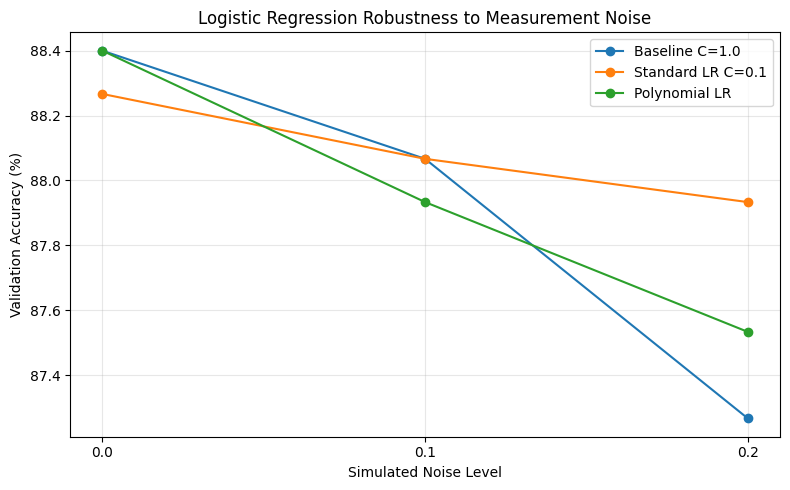

In [ ]:
# Plot validation accuracy against simulated noise level
# for the three Logistic Regression variants.

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

models_to_plot = [
    ("Baseline C=1.0", "Baseline C=1.0"),
    ("Tuned C=0.1", "Standard LR C=0.1"),
    ("Polynomial Logistic Regression", "Polynomial LR")
]

for model_name, legend_label in models_to_plot:
    subset = comparison_df[
        comparison_df["Model"] == model_name
    ].sort_values("Noise Level")

    # Polynomial results are stored in a separate DataFrame.
    if subset.empty:
        subset = polynomial_noise_comparison[
            polynomial_noise_comparison["Model"] == model_name
        ].sort_values("Noise Level")

    plt.plot(
        subset["Noise Level"],
        subset["Accuracy"] * 100,
        marker="o",
        label=legend_label
    )

plt.xlabel("Simulated Noise Level")
plt.ylabel("Validation Accuracy (%)")
plt.title("Logistic Regression Robustness to Measurement Noise")
plt.xticks([0.0, 0.1, 0.2])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Conclusion: Noise Robustness Comparison

The plot shows that all three Logistic Regression variants lose accuracy as the simulated noise level increases. At noise level 0.2, tuned standard Logistic Regression (`C = 0.1`) achieves the highest accuracy among the three models in this single-realization comparison.

However, the repeated-noise experiment shows that the baseline and tuned models have nearly identical mean accuracy at noise level 0.2. Therefore, the single-realization plot should not be interpreted as proof that the tuned model is consistently more robust.

### Comparative Confusion Matrices for Logistic Regression Variants

We compare the confusion matrices of the baseline Logistic Regression model (`C = 1.0`), tuned Logistic Regression model (`C = 0.1`), and Polynomial Logistic Regression model on the same held-out validation dataset.

Using the same validation examples allows us to compare the classification errors made by each model. The matrices help us determine whether regularization tuning or polynomial feature expansion changes the model's ability to distinguish Sedan, SUV, and Sports Car classes.

Rows represent actual classes and columns represent predicted classes. Correct predictions appear along the diagonal, while off-diagonal entries represent misclassifications.

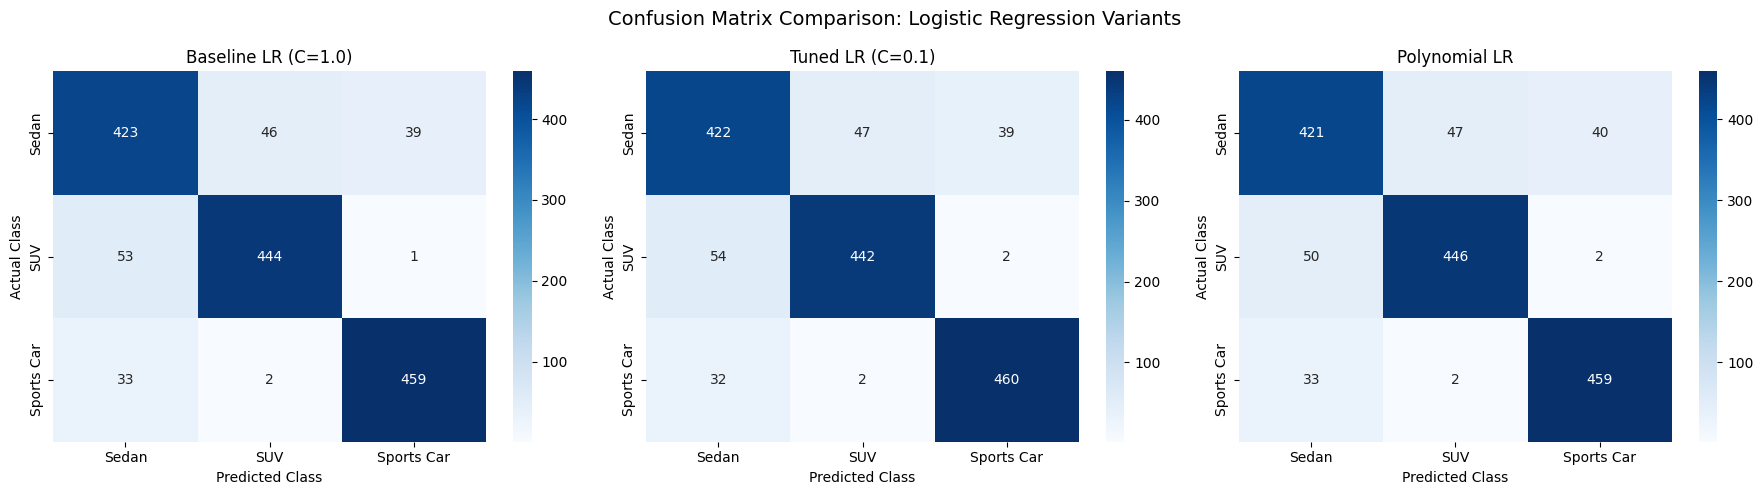

In [ ]:
# Compare confusion matrices for all three models
# using the same clean validation dataset.

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

models = [
    ("Baseline LR (C=1.0)", baseline_model),
    ("Tuned LR (C=0.1)", tuned_model),
    ("Polynomial LR", polynomial_model)
]

class_names = ["Sedan", "SUV", "Sports Car"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, model) in zip(axes, models):
    # Predict on the same clean validation examples.
    y_pred = model.predict(X_val)

    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1, 2]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.suptitle(
    "Confusion Matrix Comparison: Logistic Regression Variants",
    fontsize=14
)
plt.tight_layout()
plt.show()

### Conclusion: Confusion Matrix Comparison

The three confusion matrices show that Sedan is frequently misclassified as SUV or Sports Car, whereas SUV and Sports Car are more clearly distinguished from each other. The tuned and polynomial variants make small changes to the class-wise error counts, but neither demonstrates a substantial overall improvement over the baseline. These results support retaining standard Logistic Regression as the preferred Logistic Regression variant based on the cross-validation results.

### Visualization: Effect of Regularization Strength on Logistic Regression

We evaluated multiple values of the regularization parameter `C` using stratified five-fold cross-validation. This plot visualizes the relationship between `C` and mean cross-validation accuracy for both standard and polynomial Logistic Regression.

The x-axis uses a logarithmic scale because the tested values of `C` span several orders of magnitude. The plot helps us compare the performance of the two model variants and understand how regularization strength affects their classification accuracy.

For standard Logistic Regression, `C = 0.1` achieved the highest mean cross-validation accuracy among the tested values. Polynomial Logistic Regression did not improve upon the standard model's best cross-validation result.

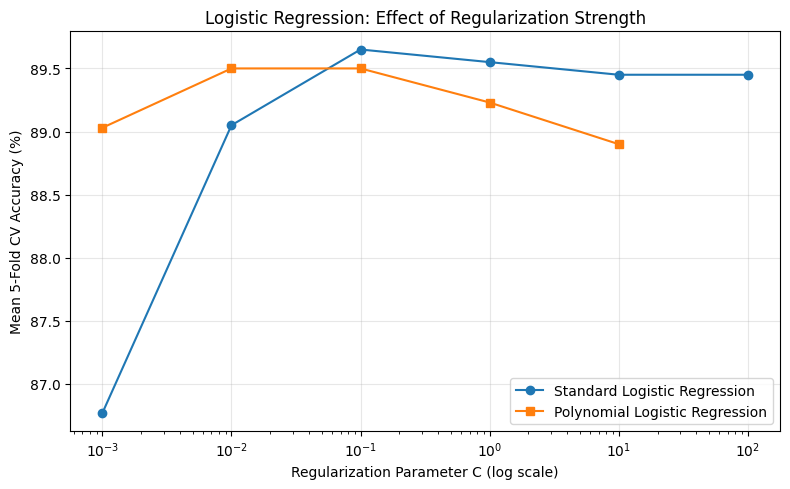

In [ ]:
# Compare cross-validation accuracy across C values
# for standard and polynomial Logistic Regression.

import matplotlib.pyplot as plt

standard_c = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
standard_accuracy = [0.8677, 0.8905, 0.8965, 0.8955, 0.8945, 0.8945]

polynomial_c = [0.001, 0.01, 0.1, 1.0, 10.0]
polynomial_accuracy = [0.8903, 0.8950, 0.8950, 0.8923, 0.8890]

plt.figure(figsize=(8, 5))

plt.plot(
    standard_c,
    [x * 100 for x in standard_accuracy],
    marker="o",
    label="Standard Logistic Regression"
)

plt.plot(
    polynomial_c,
    [x * 100 for x in polynomial_accuracy],
    marker="s",
    label="Polynomial Logistic Regression"
)

plt.xscale("log")
plt.xlabel("Regularization Parameter C (log scale)")
plt.ylabel("Mean 5-Fold CV Accuracy (%)")
plt.title("Logistic Regression: Effect of Regularization Strength")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Conclusion: Hyperparameter Tuning

Standard Logistic Regression achieved its highest mean five-fold cross-validation accuracy of 89.65% at C = 0.1. Polynomial Logistic Regression achieved a best mean accuracy of 89.50%. Since polynomial features did not improve performance, standard Logistic Regression with C = 0.1 is retained as the preferred candidate within the Logistic Regression experiments.

### Robustness Evaluation Across Multiple Noise Realizations

In the previous experiment, tuned Logistic Regression (`C = 0.1`) performed better than the baseline (`C = 1.0`) at noise level 0.2. However, that comparison used a single random realization of simulated Gaussian noise at each noise level.

To determine whether this improvement is consistent, we will generate 10 independent noisy versions of the held-out validation features at noise levels 0.1 and 0.2. Both models will be evaluated on exactly the same noisy examples in every repetition, while the original validation labels remain unchanged.

We will report the mean accuracy, standard deviation, and mean macro F1-score across repetitions. This will help us assess how sensitive the comparison is to the particular noise samples generated. The experiment uses simulated noise and does not establish the exact noise characteristics of the hidden Kaggle test data.

In [ ]:
# Compare baseline and tuned Logistic Regression
# across multiple independent noise realizations.

import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score

rng = np.random.default_rng(2026)

models = {
    "Baseline C=1.0": baseline_model,
    "Tuned C=0.1": tuned_model
}

noise_levels = [0.1, 0.2]
n_repeats = 10

# Estimate feature scales using training data only.
feature_std = X_train.std(axis=0).to_numpy()

records = []

for noise_level in noise_levels:
    for repeat in range(1, n_repeats + 1):

        # Generate one noise realization shared by both models.
        noise = rng.normal(
            loc=0.0,
            scale=noise_level * feature_std,
            size=X_val.shape
        )

        X_noisy = X_val + noise

        for model_name, model in models.items():
            predictions = model.predict(X_noisy)

            records.append({
                "Model": model_name,
                "Noise Level": noise_level,
                "Repeat": repeat,
                "Accuracy": accuracy_score(y_val, predictions),
                "Macro F1": f1_score(
                    y_val, predictions, average="macro"
                )
            })

noise_results = pd.DataFrame(records)

# Summarize performance across the 10 repetitions.
noise_summary = (
    noise_results
    .groupby(["Model", "Noise Level"])
    .agg(
        Mean_Accuracy=("Accuracy", "mean"),
        Std_Accuracy=("Accuracy", "std"),
        Mean_Macro_F1=("Macro F1", "mean"),
        Std_Macro_F1=("Macro F1", "std")
    )
    .reset_index()
)

print("ROBUSTNESS ACROSS 10 NOISE REALIZATIONS")
print("---------------------------------------")
print(noise_summary.round(4).to_string(index=False))

ROBUSTNESS ACROSS 10 NOISE REALIZATIONS
---------------------------------------
         Model  Noise Level  Mean_Accuracy  Std_Accuracy  Mean_Macro_F1  Std_Macro_F1
Baseline C=1.0          0.1         0.8823        0.0037         0.8827        0.0037
Baseline C=1.0          0.2         0.8733        0.0045         0.8738        0.0044
   Tuned C=0.1          0.1         0.8805        0.0032         0.8809        0.0033
   Tuned C=0.1          0.2         0.8734        0.0048         0.8739        0.0048


### Observations from Repeated-Noise Robustness Evaluation

The baseline Logistic Regression model (`C = 1.0`) and tuned Logistic Regression model (`C = 0.1`) were evaluated across 10 independent Gaussian noise realizations at noise levels 0.1 and 0.2.

At noise level 0.1, the baseline achieved mean accuracy of 88.23%, compared with 88.05% for the tuned model. At noise level 0.2, their mean accuracies were nearly identical at 87.33% and 87.34%, respectively.

The standard deviations across noise realizations were relatively small, ranging from 0.0032 to 0.0048 in accuracy. These results indicate that the small differences between the models are not consistent across the two noise levels.

Therefore, neither regularization setting demonstrates a clear overall advantage in this repeated-noise experiment. We retain `C = 0.1` as the best standard Logistic Regression setting by mean clean cross-validation macro F1, while recognizing that its advantage under simulated noise is not established. The results apply only to the tested Gaussian perturbations and do not establish performance on the hidden Kaggle test data.

## Final Model Training and Kaggle Submission

Based on the experiments conducted, standard Logistic Regression with `C = 0.1` is selected as our preferred Logistic Regression candidate. It achieved the highest mean cross-validation macro F1-score among the standard Logistic Regression settings tested.

We will now retrain this model on the complete cleaned training dataset, containing 7,500 unique feature combinations. The fitted model will generate predictions for the 2,500 examples in the Kaggle test dataset.

The test dataset does not contain ground-truth class labels, so local test accuracy cannot be calculated. We will save the predictions in the required submission format for evaluation on Kaggle.

In [ ]:
# Train the selected Logistic Regression model on all
# cleaned training rows and create the Kaggle submission.

from pathlib import Path
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Load the original Kaggle test data.
test_df = pd.read_csv(DATA_DIR / "vehicle_test.csv")

# Check that all required feature columns are present.
missing_features = [
    col for col in FEATURE_COLUMNS
    if col not in test_df.columns
]

assert not missing_features, (
    f"Missing test features: {missing_features}"
)

# Select features in exactly the same order as training.
X_test = test_df[FEATURE_COLUMNS].copy()

# Build the selected standard Logistic Regression pipeline.
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        C=0.1,
        max_iter=3000,
        random_state=42
    ))
])

# Train on all 7,500 cleaned labeled examples.
final_model.fit(X, y)

# Predict classes for the 2,500 test examples.
test_predictions = final_model.predict(X_test)

# Create the required Kaggle submission columns.
submission = pd.DataFrame({
    "vehicle_id": test_df["vehicle_id"],
    "vehicle_class": test_predictions
})

# Validate the submission format.
assert len(submission) == len(test_df)
assert submission.columns.tolist() == [
    "vehicle_id", "vehicle_class"
]
assert submission["vehicle_class"].isin([0, 1, 2]).all()
assert submission["vehicle_class"].notna().all()

# Save the submission to Google Drive.
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/MLproject/results"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

submission_path = (
    OUTPUT_DIR / "logistic_regression_submission.csv"
)
submission.to_csv(submission_path, index=False)

print("Final model trained on:", len(X), "rows")
print("Test rows predicted:", len(submission))
print("\nPredicted class counts:")
print(submission["vehicle_class"].value_counts().sort_index())

print("\nSubmission preview:")
print(submission.head())

print("\nSaved submission to:")
print(submission_path)

Final model trained on: 7500 rows
Test rows predicted: 2500

Predicted class counts:
vehicle_class
0    837
1    831
2    832
Name: count, dtype: int64

Submission preview:
   vehicle_id  vehicle_class
0       10001              0
1       10002              0
2       10003              1
3       10004              2
4       10005              1

Saved submission to:
/content/drive/MyDrive/MLproject/results/logistic_regression_submission.csv


### Submission File Validation

Before uploading the generated CSV to Kaggle, we will verify that the submission file follows the required format and contains valid predictions.

The verification checks that the file contains exactly 2,500 rows and two columns, `vehicle_id` and `vehicle_class`. It also confirms that the vehicle IDs match the original test dataset in the same order, all predicted classes belong to the valid set `{0, 1, 2}`, and no missing values are present.

These checks help detect formatting and data-integrity errors before submission. Passing them confirms that the file satisfies these structural requirements, but it does not guarantee prediction accuracy on the hidden test labels.

In [ ]:
# Verify the saved submission before uploading to Kaggle.

saved_submission = pd.read_csv(submission_path)

assert saved_submission.shape == (2500, 2)
assert saved_submission.columns.tolist() == [
    "vehicle_id", "vehicle_class"
]
assert saved_submission["vehicle_id"].equals(
    test_df["vehicle_id"]
)
assert saved_submission["vehicle_class"].isin([0, 1, 2]).all()

print("Submission validation passed.")
print("Rows:", len(saved_submission))
print("Columns:", saved_submission.columns.tolist())
print("Missing values:", saved_submission.isna().sum().sum())

Submission validation passed.
Rows: 2500
Columns: ['vehicle_id', 'vehicle_class']
Missing values: 0


## 10. Generate Submission Using Baseline Logistic Regression

In this section, we generate a Kaggle submission using the baseline Logistic Regression model. Unlike the tuned model, which uses `C = 0.1`, the baseline model uses `C = 1.0`.

We use a `StandardScaler` to standardize the numerical features before training Logistic Regression. Both steps are included in a pipeline to ensure consistent preprocessing during training and prediction.

The model is trained on all 7,500 cleaned training records and then used to predict the vehicle classes of the 2,500 test records. The resulting predictions are saved as a CSV file in the required Kaggle submission format.

In [ ]:
# Import the required libraries
import pandas as pd
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Define the feature columns by excluding the ID and target columns
FEATURE_COLUMNS = [
    col for col in train_clean.columns
    if col not in ["vehicle_id", "vehicle_class"]
]

# Prepare the complete cleaned training data
X = train_clean[FEATURE_COLUMNS].copy()
y = train_clean["vehicle_class"].copy()

# Prepare the test features, excluding vehicle_id
X_test = test_df[FEATURE_COLUMNS].copy()

# Create the baseline Logistic Regression pipeline
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        C=1.0,
        max_iter=3000,
        random_state=42
    ))
])

# Train the model on all cleaned training records
baseline_model.fit(X, y)

# Predict the vehicle classes for the test dataset
baseline_predictions = baseline_model.predict(X_test)

print("Baseline model training completed.")
print("Training rows:", len(X))
print("Test predictions:", len(baseline_predictions))

Baseline model training completed.
Training rows: 7500
Test predictions: 2500


### Create the Baseline Submission File

The Kaggle competition requires a CSV containing two columns: `vehicle_id` and `vehicle_class`. We retain the IDs from the original test dataset and pair them with the predictions generated by the baseline model.

We save the file in the project's results directory so that it can be downloaded and submitted to Kaggle.

In [ ]:
# Create the submission DataFrame in the required format
baseline_submission = pd.DataFrame({
    "vehicle_id": test_df["vehicle_id"],
    "vehicle_class": baseline_predictions
})

# Define the output directory
OUTPUT_DIR = Path("/content/drive/MyDrive/MLproject/results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the baseline submission
baseline_path = OUTPUT_DIR / "baseline_logistic_regression_submission.csv"
baseline_submission.to_csv(baseline_path, index=False)

# Validate the generated file
assert len(baseline_submission) == len(test_df)
assert list(baseline_submission.columns) == [
    "vehicle_id", "vehicle_class"
]
assert baseline_submission.isnull().sum().sum() == 0
assert baseline_submission["vehicle_id"].equals(test_df["vehicle_id"])
assert set(baseline_submission["vehicle_class"].unique()).issubset({0, 1, 2})

print("Baseline submission saved and validated.")
print("File:", baseline_path)
print("\nPredicted class counts:")
print(baseline_submission["vehicle_class"].value_counts().sort_index())
print("\nSubmission preview:")
# Display the first five rows of the submission
print(baseline_submission.head())

Baseline submission saved and validated.
File: /content/drive/MyDrive/MLproject/results/baseline_logistic_regression_submission.csv

Predicted class counts:
vehicle_class
0    839
1    832
2    829
Name: count, dtype: int64

Submission preview:
   vehicle_id  vehicle_class
0       10001              0
1       10002              0
2       10003              1
3       10004              2
4       10005              1


## 11. Generate Submission Using Polynomial Logistic Regression

In this section, we generate another Kaggle submission using Polynomial Logistic Regression.

Polynomial features of degree 2 are created to allow the model to capture quadratic effects and pairwise interactions between the original features. These additional features are then standardized before Logistic Regression is applied.

Based on our earlier experiments, we use `C = 0.1` for this model. The polynomial model is trained on all 7,500 cleaned training records and generates predictions for the 2,500 test records.

This experiment allows us to compare the Kaggle performance of a model using polynomial feature expansion with the standard Logistic Regression models.

In [ ]:
# Import the polynomial feature transformer
from sklearn.preprocessing import PolynomialFeatures

# Create the Polynomial Logistic Regression pipeline
polynomial_model = Pipeline([
    # Generate degree-2 polynomial features and pairwise interactions
    ("polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),

    # Standardize the expanded feature set
    ("scaler", StandardScaler()),

    # Train Logistic Regression on the polynomial features
    ("logistic_regression", LogisticRegression(
        C=0.1,
        max_iter=5000,
        random_state=42
    ))
])

# Train the polynomial model on all cleaned training records
polynomial_model.fit(X, y)

# Predict the classes of the test records
polynomial_predictions = polynomial_model.predict(X_test)

print("Polynomial Logistic Regression training completed.")
print("Training rows:", len(X))
print("Original feature count:", X.shape[1])
print("Expanded feature count:",
      polynomial_model.named_steps["polynomial"].transform(X.iloc[:1]).shape[1])
print("Test predictions:", len(polynomial_predictions))

Polynomial Logistic Regression training completed.
Training rows: 7500
Original feature count: 20
Expanded feature count: 230
Test predictions: 2500


### Create the Polynomial Logistic Regression Submission

We now create a submission file using the predictions from the polynomial model. As with the baseline model, the file must contain the original test IDs and one predicted vehicle class for every test record.

The file is saved separately so that it can be uploaded to Kaggle without overwriting the baseline or tuned standard Logistic Regression submissions.

In [ ]:
# Create the polynomial model submission DataFrame
polynomial_submission = pd.DataFrame({
    "vehicle_id": test_df["vehicle_id"],
    "vehicle_class": polynomial_predictions
})

# Save the polynomial submission separately
polynomial_path = OUTPUT_DIR / "polynomial_logistic_regression_submission.csv"
polynomial_submission.to_csv(polynomial_path, index=False)

# Validate the generated file
assert len(polynomial_submission) == len(test_df)
assert list(polynomial_submission.columns) == [
    "vehicle_id", "vehicle_class"
]
assert polynomial_submission.isnull().sum().sum() == 0
assert polynomial_submission["vehicle_id"].equals(test_df["vehicle_id"])
assert set(polynomial_submission["vehicle_class"].unique()).issubset({0, 1, 2})

print("Polynomial submission saved and validated.")
print("File:", polynomial_path)
print("\nPredicted class counts:")
print(polynomial_submission["vehicle_class"].value_counts().sort_index())
print("\nSubmission preview:")
print(polynomial_submission.head())

Polynomial submission saved and validated.
File: /content/drive/MyDrive/MLproject/results/polynomial_logistic_regression_submission.csv

Predicted class counts:
vehicle_class
0    847
1    827
2    826
Name: count, dtype: int64

Submission preview:
   vehicle_id  vehicle_class
0       10001              0
1       10002              0
2       10003              1
3       10004              2
4       10005              1


## 12. Verify All Three Model Submissions

We have now generated submissions from three model configurations:

1. Baseline standard Logistic Regression (`C = 1.0`).
2. Tuned standard Logistic Regression (`C = 0.1`).
3. Degree-2 Polynomial Logistic Regression (`C = 0.1`).

We verify that all three files have the expected number of rows and the required columns. This check confirms that each file is structurally ready for submission; it does not establish which model is most accurate on the hidden test data.

In [ ]:
# Paths of the three model submission files
submission_files = {
    "Baseline Logistic Regression": baseline_path,
    "Tuned Standard Logistic Regression":
        OUTPUT_DIR / "logistic_regression_submission.csv",
    "Polynomial Logistic Regression": polynomial_path
}

# Load and validate each submission file
for model_name, file_path in submission_files.items():
    df = pd.read_csv(file_path)

    assert len(df) == len(test_df), f"Incorrect row count: {model_name}"
    assert list(df.columns) == ["vehicle_id", "vehicle_class"]
    assert df.isnull().sum().sum() == 0
    assert df["vehicle_id"].equals(test_df["vehicle_id"])
    assert set(df["vehicle_class"].unique()).issubset({0, 1, 2})

    print(f"{model_name}: VALID")
    print(f"  Rows: {len(df)}")
    print(f"  File: {file_path}")

Baseline Logistic Regression: VALID
  Rows: 2500
  File: /content/drive/MyDrive/MLproject/results/baseline_logistic_regression_submission.csv
Tuned Standard Logistic Regression: VALID
  Rows: 2500
  File: /content/drive/MyDrive/MLproject/results/logistic_regression_submission.csv
Polynomial Logistic Regression: VALID
  Rows: 2500
  File: /content/drive/MyDrive/MLproject/results/polynomial_logistic_regression_submission.csv


## Baseline Logistic Regression with Noisy Training Features

In this experiment, we will train the baseline Logistic Regression model using artificially noisy training features. We will add Gaussian noise to the 20 numerical features while keeping the target labels unchanged.

We will use the same `StandardScaler` and Logistic Regression configuration (`C=1.0`) as the original baseline model. The noise magnitude will be proportional to each feature's standard deviation, with a noise level of 0.1.

After training, we will evaluate the model on the clean validation data and compare its performance with the original baseline model. This will help us understand whether training with noisy data affects classification performance.

We will reuse the existing train-validation split and exclude `vehicle_id` from the model features.

In [ ]:
# Import the libraries required for noise generation, model training,
# and evaluation of classification performance.
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix


# ---------------------------------------------------------
# STEP 1: Set a random seed for reproducibility
# ---------------------------------------------------------

# Using the same seed ensures that we generate the same noise
# each time we run this cell, provided the inputs remain unchanged.
rng = np.random.default_rng(42)


# ---------------------------------------------------------
# STEP 2: Convert training and validation features to NumPy arrays
# ---------------------------------------------------------

# These are copies/references converted to arrays for numerical operations.
# We do not modify the original X_train or X_val variables.
X_train_array = np.asarray(X_train, dtype=float)
X_val_array = np.asarray(X_val, dtype=float)


# ---------------------------------------------------------
# STEP 3: Calculate the standard deviation of each feature
# ---------------------------------------------------------

# Each feature can have a different scale.
# For example, one feature might range from 0 to 10,
# while another might range from 0 to 1000.
#
# We calculate standard deviations using ONLY training data
# to avoid using validation data when determining noise magnitude.
feature_std = X_train_array.std(axis=0)


# ---------------------------------------------------------
# STEP 4: Generate Gaussian noise and create noisy training data
# ---------------------------------------------------------

# The noise level is 0.1, meaning the noise standard deviation
# for each feature is 10% of that feature's training standard deviation.
noise_level = 0.1

# Generate random Gaussian noise with mean 0.
# Each feature receives noise scaled according to its own standard deviation.
# The noise array has exactly the same shape as the training data.
noise = rng.normal(
    loc=0.0,                         # Mean of the Gaussian noise
    scale=noise_level * feature_std, # Noise standard deviation per feature
    size=X_train_array.shape         # Same dimensions as training features
)

# Add noise to the training features to create a NEW array.
# X_train_array and the original clean dataset remain unchanged.
X_train_noisy = X_train_array + noise


# ---------------------------------------------------------
# STEP 5: Verify the shapes of the datasets
# ---------------------------------------------------------

# The noisy dataset should have the same number of rows and features
# as the original training dataset.
print("Original training shape:", X_train_array.shape)
print("Noisy training shape:", X_train_noisy.shape)
print("Training labels shape:", np.asarray(y_train).shape)


# ---------------------------------------------------------
# STEP 6: Create the baseline Logistic Regression pipeline
# ---------------------------------------------------------

# StandardScaler standardizes features using their mean and standard deviation.
# LogisticRegression then learns to classify the vehicle types.
#
# C=1.0 is the regularization setting used in our baseline model.
# max_iter=2000 allows enough iterations for the model to converge.
noisy_baseline_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(C=1.0, max_iter=2000))
])


# ---------------------------------------------------------
# STEP 7: Train the model on noisy features
# ---------------------------------------------------------

# X_train_noisy contains the artificially perturbed features.
# y_train still contains the original, correct vehicle-class labels.
noisy_baseline_lr.fit(X_train_noisy, y_train)


# ---------------------------------------------------------
# STEP 8: Predict classes for CLEAN validation features
# ---------------------------------------------------------

# We evaluate on clean validation features first.
# This helps us see how training with noise affects performance
# when the evaluation data does not contain artificial noise.
y_val_pred_noisy_model = noisy_baseline_lr.predict(X_val_array)


# ---------------------------------------------------------
# STEP 9: Calculate evaluation metrics
# ---------------------------------------------------------

# Accuracy = proportion of validation examples classified correctly.
noisy_model_accuracy = accuracy_score(
    y_val, y_val_pred_noisy_model
)

# Macro F1 calculates F1 separately for each class and averages them equally.
# This helps evaluate performance across Sedan, SUV, and Sports Car.
noisy_model_macro_f1 = f1_score(
    y_val, y_val_pred_noisy_model, average="macro"
)

# Display the evaluation results.
print("\nBaseline Logistic Regression trained on noisy features")
print(f"Clean validation accuracy: {noisy_model_accuracy:.4f}")
print(f"Clean validation macro F1: {noisy_model_macro_f1:.4f}")

# The confusion matrix shows actual classes against predicted classes.
# The diagonal contains correct predictions; off-diagonal entries are errors.
print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_val_pred_noisy_model))

Original training shape: (6000, 20)
Noisy training shape: (6000, 20)
Training labels shape: (6000,)

Baseline Logistic Regression trained on noisy features
Clean validation accuracy: 0.8860
Clean validation macro F1: 0.8864

Confusion matrix:
[[424  45  39]
 [ 53 444   1]
 [ 31   2 461]]


## Evaluating Baseline Logistic Regression on Noisy Validation Data

We will now evaluate the original clean-trained baseline and the noise-trained baseline on validation features with different levels of artificial Gaussian noise.

We will test noise levels of 0.0, 0.1, and 0.2, where the noise standard deviation is proportional to each feature's standard deviation calculated from the training data. Both models will receive the same noisy validation features at each noise level.

We will compare accuracy and macro F1 to determine whether training on noisy features improves robustness to measurement uncertainty.

In [ ]:
# Display model-related variables currently available in the notebook.
# This helps us identify the name of your original clean-trained model.

for name, value in list(globals().items()):
    if "lr" in name.lower() or "logistic" in name.lower():
        if hasattr(value, "predict"):
            print(name, "->", type(value).__name__)

LogisticRegression -> type
lr_pipeline -> Pipeline
noisy_baseline_lr -> Pipeline


In [ ]:
# Train the original baseline Logistic Regression on CLEAN training data.
# This ensures we have a fitted clean-trained model for comparison.

lr_pipeline.fit(X_train, y_train)

print("Clean-trained baseline fitted successfully.")

Clean-trained baseline fitted successfully.


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score

# Compare the original clean-trained model with the noisy-trained model.
models = {
    "Clean-trained baseline": lr_pipeline,
    "Noisy-trained baseline": noisy_baseline_lr
}

# Noise levels to test:
# 0.0 = clean validation features
# 0.1 = moderate Gaussian noise
# 0.2 = stronger Gaussian noise
noise_levels = [0.0, 0.1, 0.2]

# Use a separate random generator for validation noise.
# This does not change either trained model or the training data.
validation_rng = np.random.default_rng(123)

# Store the evaluation metrics for the final table.
results = []

for level in noise_levels:

    # Generate Gaussian noise using training-set feature scales.
    validation_noise = validation_rng.normal(
        loc=0.0,
        scale=level * feature_std,
        size=X_val_array.shape
    )

    # Create noisy validation features without modifying the clean array.
    X_val_current = X_val_array + validation_noise

    # Evaluate both models on exactly the same validation features.
    for model_name, model in models.items():

        # Predict vehicle classes.
        predictions = model.predict(X_val_current)

        # Calculate evaluation metrics.
        accuracy = accuracy_score(y_val, predictions)
        macro_f1 = f1_score(
            y_val,
            predictions,
            average="macro"
        )

        # Save the results.
        results.append({
            "Model": model_name,
            "Validation noise level": level,
            "Accuracy": accuracy,
            "Macro F1": macro_f1
        })

# Convert results into a DataFrame for easy comparison.
results_df = pd.DataFrame(results)

# Display the metrics rounded to four decimal places.
print(results_df.to_string(
    index=False,
    formatters={
        "Accuracy": "{:.4f}".format,
        "Macro F1": "{:.4f}".format
    }
))

                 Model  Validation noise level Accuracy Macro F1
Clean-trained baseline                     0.0   0.8840   0.8844
Noisy-trained baseline                     0.0   0.8860   0.8864
Clean-trained baseline                     0.1   0.8813   0.8817
Noisy-trained baseline                     0.1   0.8793   0.8799
Clean-trained baseline                     0.2   0.8793   0.8799
Noisy-trained baseline                     0.2   0.8793   0.8799


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


### Observations and Conclusion

The baseline Logistic Regression model trained on noisy features achieved a validation accuracy of 88.60% and a macro F1 score of 0.8864 on clean validation data, slightly outperforming the clean-trained baseline, which achieved 88.40% accuracy and a macro F1 score of 0.8844.

However, when evaluated on noisy validation features, the noisy-trained model did not consistently outperform the clean-trained model. At noise level 0.1, the clean-trained model performed slightly better, while at noise level 0.2, both models achieved identical accuracy and macro F1 scores.

Therefore, adding Gaussian noise during training produced a small improvement on clean validation data but did not demonstrate a consistent robustness benefit in this experiment. Further evaluation using five-fold cross-validation is needed before drawing a stronger conclusion.

## Five-Fold Cross-Validation: Clean vs. Noise-Augmented Logistic Regression

In this experiment, we will use five-fold cross-validation to compare the baseline Logistic Regression model trained on clean features with the same model trained on noise-augmented features.

The dataset will be divided into five stratified folds. In each iteration, four folds will be used for training and the remaining fold for validation. Gaussian noise with a relative noise level of 0.1 will be added only to the training features of the noise-augmented model. The target labels will remain unchanged.

Both models will be evaluated on the clean validation fold and on a noisy version of that same fold, using a noise level of 0.1. We will report the mean and standard deviation of accuracy and macro F1 across the five folds.

The scaler will be fitted separately within each model pipeline in every fold. This experiment will help us determine whether noise augmentation provides a consistent improvement in clean-data performance or robustness to noisy inputs.

In [ ]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# ---------------------------------------------------------
# STEP 1: Configure the experiment
# ---------------------------------------------------------

# Use five stratified folds so that class proportions are
# approximately preserved in every fold.
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Use the same baseline Logistic Regression configuration.
# StandardScaler is fitted separately within each fold.
clean_template = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(C=1.0, max_iter=2000))
])

# Use the same model configuration for noise-augmented training.
noisy_template = clone(clean_template)

# Add noise at 10% of each feature's standard deviation.
noise_level = 0.1

# Store metrics from every fold.
cv_results = []

# Separate random generator for reproducible noise.
rng = np.random.default_rng(42)


# ---------------------------------------------------------
# STEP 2: Run five-fold cross-validation
# ---------------------------------------------------------

# Convert the training features and labels to arrays.
X = np.asarray(X_train, dtype=float)
y = np.asarray(y_train)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):

    # Separate this fold's training and validation data.
    X_fold_train = X[train_idx]
    y_fold_train = y[train_idx]

    X_fold_val = X[val_idx]
    y_fold_val = y[val_idx]

    # Calculate feature scales using only this fold's training data.
    # This prevents information from the validation fold leaking
    # into the noise-generation process.
    fold_std = X_fold_train.std(axis=0)

    # Generate noisy training features.
    train_noise = rng.normal(
        loc=0.0,
        scale=noise_level * fold_std,
        size=X_fold_train.shape
    )

    X_fold_train_noisy = X_fold_train + train_noise

    # Generate one noisy version of the validation fold.
    # Both models will be evaluated on this exact same version.
    val_noise = rng.normal(
        loc=0.0,
        scale=noise_level * fold_std,
        size=X_fold_val.shape
    )

    X_fold_val_noisy = X_fold_val + val_noise

    # -----------------------------------------------------
    # STEP 3: Train the clean-trained model
    # -----------------------------------------------------

    clean_model = clone(clean_template)
    clean_model.fit(X_fold_train, y_fold_train)

    # -----------------------------------------------------
    # STEP 4: Train the noise-augmented model
    # -----------------------------------------------------

    noisy_model = clone(noisy_template)
    noisy_model.fit(X_fold_train_noisy, y_fold_train)

    # -----------------------------------------------------
    # STEP 5: Evaluate both models on clean and noisy data
    # -----------------------------------------------------

    for model_name, model in [
        ("Clean-trained", clean_model),
        ("Noisy-trained", noisy_model)
    ]:

        # Evaluate on the clean validation fold.
        clean_pred = model.predict(X_fold_val)

        cv_results.append({
            "Fold": fold,
            "Model": model_name,
            "Evaluation data": "Clean",
            "Accuracy": accuracy_score(y_fold_val, clean_pred),
            "Macro F1": f1_score(
                y_fold_val, clean_pred, average="macro"
            )
        })

        # Evaluate on the noisy validation fold.
        noisy_pred = model.predict(X_fold_val_noisy)

        cv_results.append({
            "Fold": fold,
            "Model": model_name,
            "Evaluation data": "Noisy (0.1)",
            "Accuracy": accuracy_score(y_fold_val, noisy_pred),
            "Macro F1": f1_score(
                y_fold_val, noisy_pred, average="macro"
            )
        })


# ---------------------------------------------------------
# STEP 6: Display individual-fold results
# ---------------------------------------------------------

cv_df = pd.DataFrame(cv_results)

print("Results for each fold:")
print(cv_df.to_string(
    index=False,
    formatters={
        "Accuracy": "{:.4f}".format,
        "Macro F1": "{:.4f}".format
    }
))


# ---------------------------------------------------------
# STEP 7: Calculate mean and standard deviation across folds
# ---------------------------------------------------------

summary_df = (
    cv_df.groupby(["Model", "Evaluation data"])[["Accuracy", "Macro F1"]]
    .agg(["mean", "std"])
)

print("\nMean and standard deviation across five folds:")
print(summary_df.round(4))

Results for each fold:
 Fold         Model Evaluation data Accuracy Macro F1
    1 Clean-trained           Clean   0.9025   0.9029
    1 Clean-trained     Noisy (0.1)   0.9033   0.9036
    1 Noisy-trained           Clean   0.9033   0.9038
    1 Noisy-trained     Noisy (0.1)   0.9050   0.9054
    2 Clean-trained           Clean   0.8900   0.8904
    2 Clean-trained     Noisy (0.1)   0.8908   0.8912
    2 Noisy-trained           Clean   0.8908   0.8912
    2 Noisy-trained     Noisy (0.1)   0.8900   0.8904
    3 Clean-trained           Clean   0.8875   0.8880
    3 Clean-trained     Noisy (0.1)   0.8808   0.8814
    3 Noisy-trained           Clean   0.8892   0.8898
    3 Noisy-trained     Noisy (0.1)   0.8858   0.8865
    4 Clean-trained           Clean   0.9025   0.9025
    4 Clean-trained     Noisy (0.1)   0.9000   0.9000
    4 Noisy-trained           Clean   0.9025   0.9026
    4 Noisy-trained     Noisy (0.1)   0.8975   0.8976
    5 Clean-trained           Clean   0.8950   0.8956
    5

### Observations and Conclusion

Five-fold stratified cross-validation was used to compare the baseline Logistic Regression model trained on clean features with a noise-augmented version trained using Gaussian noise at a relative level of 0.1.

On clean validation folds, the clean-trained model achieved a mean accuracy of 89.55% and a mean macro F1 score of 0.8959. The noise-augmented model achieved a mean accuracy of 89.60% and a mean macro F1 score of 0.8964.

On noisy validation folds, the clean-trained model achieved a mean accuracy of 89.30% and a mean macro F1 score of 0.8933. The noise-augmented model achieved a mean accuracy of 89.37% and a mean macro F1 score of 0.8940.

The noise-augmented model therefore showed a very small advantage in both evaluation settings. Its fold-to-fold variability was also slightly lower. However, the performance differences were minimal, so these results do not establish a substantial or statistically significant benefit from noise augmentation.

Overall, noise augmentation at level 0.1 appears to preserve baseline performance and may provide a slight robustness benefit. Further experiments with repeated noise realizations and additional noise levels would be needed to confirm this finding.

## Final Submission: Noise-Augmented Baseline Logistic Regression

In this experiment, we train the baseline Logistic Regression model using Gaussian noise-augmented features and generate predictions for the competition test dataset.

Unlike the earlier experiments, which used a training-validation split, this final model uses all available cleaned training records to maximize the data available for learning. Noise is added only to the training features, while the original vehicle-class labels remain unchanged.

The model uses StandardScaler followed by Logistic Regression with C = 1.0. Its predictions are saved to a separate CSV file so that this submission can be evaluated independently of the other model submissions.

In [ ]:
# =========================================================
# STEP 1: Import libraries and define file paths
# =========================================================

import os
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Paths to the cleaned training data, test data, and results folder.
DATA_DIR = "/content/drive/MyDrive/MLproject/data"
RESULTS_DIR = "/content/drive/MyDrive/MLproject/results"

TRAIN_PATH = os.path.join(DATA_DIR, "vehicle_train_clean.csv")
TEST_PATH = os.path.join(DATA_DIR, "vehicle_test.csv")

# Create the results folder if it does not already exist.
os.makedirs(RESULTS_DIR, exist_ok=True)

# Give this model its own submission filename.
SUBMISSION_PATH = os.path.join(
    RESULTS_DIR,
    "noisy_logistic_regression_submission.csv"
)


# =========================================================
# STEP 2: Load the cleaned training data and test data
# =========================================================

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training dataset shape:", train_df.shape)
print("Test dataset shape:", test_df.shape)

# Separate the target labels from the training features.
y_all = train_df["vehicle_class"]

# Exclude the identifier and target columns from model features.
feature_cols = [
    col for col in train_df.columns
    if col not in ["vehicle_id", "vehicle_class"]
]

# Ensure test data contains the same features in the same order.
missing_features = [
    col for col in feature_cols
    if col not in test_df.columns
]

if missing_features:
    raise ValueError(
        f"Missing test features: {missing_features}"
    )

X_all = train_df[feature_cols].astype(float)
X_test = test_df[feature_cols].astype(float)

print("Number of model features:", len(feature_cols))
print("Training features shape:", X_all.shape)
print("Test features shape:", X_test.shape)


# =========================================================
# STEP 3: Generate noise for the training features
# =========================================================

# Use a fixed seed so the experiment is reproducible.
rng = np.random.default_rng(42)

# Calculate feature standard deviations from the full training data.
feature_std_all = X_all.std(axis=0).to_numpy()

# Add Gaussian noise with standard deviation equal to 10%
# of each feature's training standard deviation.
noise_level = 0.1

noise = rng.normal(
    loc=0.0,
    scale=noise_level * feature_std_all,
    size=X_all.shape
)

# Create a new noisy training array.
# The original DataFrame and CSV remain unchanged.
X_all_noisy = X_all.to_numpy() + noise

print("Noisy training features shape:", X_all_noisy.shape)


# =========================================================
# STEP 4: Create and train the baseline Logistic Regression
# =========================================================

# StandardScaler is fitted on the noisy training features.
# Logistic Regression uses the original vehicle-class labels.
final_noisy_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=1.0,
        max_iter=2000
    ))
])

# Train on all available cleaned training records.
final_noisy_lr.fit(X_all_noisy, y_all)

print("Noise-augmented Logistic Regression trained successfully.")


# =========================================================
# STEP 5: Predict the test dataset
# =========================================================

# Do not add artificial noise to the test features here.
# The trained pipeline applies its fitted StandardScaler.
test_predictions = final_noisy_lr.predict(X_test)

print("Number of test predictions:", len(test_predictions))


# =========================================================
# STEP 6: Build and save the submission CSV
# =========================================================

# Use the test identifiers and predicted vehicle classes.
submission_df = pd.DataFrame({
    "vehicle_id": test_df["vehicle_id"],
    "vehicle_class": test_predictions
})

# Verify the expected competition submission format.
assert list(submission_df.columns) == [
    "vehicle_id", "vehicle_class"
]
assert len(submission_df) == len(test_df)
assert submission_df["vehicle_class"].isin([0, 1, 2]).all()

# Save to a NEW file; existing submissions are not overwritten.
submission_df.to_csv(SUBMISSION_PATH, index=False)

print("\nSubmission saved successfully!")
print("File:", SUBMISSION_PATH)
print("Submission shape:", submission_df.shape)

print("\nFirst five predictions:")
print(submission_df.head())

print("\nPredicted class distribution:")
print(submission_df["vehicle_class"].value_counts().sort_index())

Training dataset shape: (7500, 22)
Test dataset shape: (2500, 21)
Number of model features: 20
Training features shape: (7500, 20)
Test features shape: (2500, 20)
Noisy training features shape: (7500, 20)
Noise-augmented Logistic Regression trained successfully.
Number of test predictions: 2500

Submission saved successfully!
File: /content/drive/MyDrive/MLproject/results/noisy_logistic_regression_submission.csv
Submission shape: (2500, 2)

First five predictions:
   vehicle_id  vehicle_class
0       10001              0
1       10002              0
2       10003              1
3       10004              2
4       10005              1

Predicted class distribution:
vehicle_class
0    841
1    826
2    833
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


## Covariance-Based Bayesian Classification (QDA)

Step 1: Verify datasets for the covariance-based Bayesian classifier (QDA)

The dataset has already been cleaned, and the training-validation split has already been created. Therefore, no additional cleaning or splitting is required.

In this step, we will reuse the existing training and validation datasets and load the separate test dataset from Google Drive. We will verify the dataset dimensions and ensure the test dataset contains the same predictor features used for training.

We will then train and evaluate the Quadratic Discriminant Analysis (QDA) classifier using the existing data.



### Step 1: Load the existing datasets

The cleaned training dataset already contains the processed features and target labels. We will load it and recreate the train-validation split using the saved split indices, without performing data cleaning again. We will also load the competition test dataset and select the same 20 features. The `vehicle_id` and `vehicle_class` columns will not be used as predictor features.

In [ ]:
# Restore the original split using the exact saved labels

train_idx = split_indices.loc[
    split_indices["split"] == "train", "row_index"
]
val_idx = split_indices.loc[
    split_indices["split"] == "validation", "row_index"
]

X_train, y_train = X.loc[train_idx], y.loc[train_idx]
X_val, y_val = X.loc[val_idx], y.loc[val_idx]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape)
print("Training class counts:\n", y_train.value_counts().sort_index())
print("Validation class counts:\n", y_val.value_counts().sort_index())

assert len(X_train) == 6000
assert len(X_val) == 1500

print("\nOriginal split restored successfully. Ready for QDA.")

Training: (6000, 20) (6000,)
Validation: (1500, 20) (1500,)
Test: (2500, 20)
Training class counts:
 vehicle_class
0    2031
1    1992
2    1977
Name: count, dtype: int64
Validation class counts:
 vehicle_class
0    508
1    498
2    494
Name: count, dtype: int64

Original split restored successfully. Ready for QDA.


Train the Quadratic Discriminant Analysis (QDA) classifier

We will train a Quadratic Discriminant Analysis (QDA) classifier using the existing cleaned training data.

QDA is a Gaussian generative classifier that models each vehicle class using its own mean vector and covariance matrix. Unlike Gaussian Naive Bayes, QDA accounts for relationships between features through the full covariance matrix.

For each class, QDA estimates:

Mean vector: the average value of each feature for that class.

Covariance matrix: the variances of individual features and covariances between pairs of features.

Class prior: the estimated probability of the class based on its frequency in the training data.

It then uses Bayes' theorem to estimate the class probabilities and predicts the class with the highest posterior probability.

We will first fit the standard QDA model without regularization, using the existing training set. We will evaluate it on the validation set in the next step.

In [ ]:
# Step 2: Train the baseline QDA classifier

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

# Create the QDA model
qda_model = QuadraticDiscriminantAnalysis()

# Fit the model using the existing cleaned training data
qda_model.fit(X_train, y_train)

# Display basic model information
print("QDA model trained successfully.")
print("Number of classes:", len(qda_model.classes_))
print("Classes:", qda_model.classes_)
print("Features used:", X_train.shape[1])
print("Class priors:", qda_model.priors_)
print("Regularization parameter:", qda_model.reg_param)

QDA model trained successfully.
Number of classes: 3
Classes: [0 1 2]
Features used: 20
Class priors: [0.3385 0.332  0.3295]
Regularization parameter: 0.0


### Step 3: Evaluate the baseline QDA classifier

Now that the model is trained, we will evaluate it on the 1,500 validation examples that were not used during training.

We will calculate:

- **Accuracy:** the proportion of correctly classified vehicles.
- **Macro F1-score:** the average F1-score across the three classes, giving each class equal weight.
- **Confusion matrix:** a breakdown of correct and incorrect predictions for each class.

These metrics will help us understand the baseline performance before investigating robustness to noisy features. We will use the validation results to decide whether covariance regularization is worth exploring.

In [ ]:
# Step 3: Evaluate baseline QDA on the clean validation set

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# Predict vehicle classes for unseen validation examples
y_val_pred = qda_model.predict(X_val)

# Calculate evaluation metrics
qda_accuracy = accuracy_score(y_val, y_val_pred)
qda_macro_f1 = f1_score(y_val, y_val_pred, average="macro")
qda_cm = confusion_matrix(y_val, y_val_pred)

# Display the results
print(f"Validation accuracy: {qda_accuracy:.4f}")
print(f"Validation macro F1-score: {qda_macro_f1:.4f}")

print("\nConfusion matrix (rows = actual, columns = predicted):")
print(qda_cm)

print("\nClassification report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

Validation accuracy: 0.8747
Validation macro F1-score: 0.8750

Confusion matrix (rows = actual, columns = predicted):
[[413  54  41]
 [ 57 441   0]
 [ 34   2 458]]

Classification report:
              precision    recall  f1-score   support

           0       0.82      0.81      0.82       508
           1       0.89      0.89      0.89       498
           2       0.92      0.93      0.92       494

    accuracy                           0.87      1500
   macro avg       0.87      0.88      0.88      1500
weighted avg       0.87      0.87      0.87      1500



### Conclusion: Baseline QDA

The baseline Quadratic Discriminant Analysis classifier achieved a validation accuracy of **87.47%** and a macro F1-score of **0.8750**.

Class 2 performed best, with an F1-score of 0.92, followed by class 1 at 0.89. Class 0 was the most challenging, with an F1-score of 0.82. The confusion matrix indicates that class 0 and class 1 are frequently confused with each other.

The results establish a baseline for evaluating the covariance-based Bayesian classifier. Further experiments will investigate its robustness to noisy features and whether covariance regularization improves performance.

### Step 4: Evaluate QDA under different noise levels

Real-world vehicle measurements may contain noise. To study how sensitive QDA is to such perturbations, we will evaluate the trained model on validation features with three noise levels:

- **0.0:** Original clean validation features.
- **0.1:** Gaussian noise with a standard deviation equal to 10% of each training feature's standard deviation.
- **0.2:** Gaussian noise with a standard deviation equal to 20% of each training feature's standard deviation.

We will keep the trained model and validation labels unchanged. Noise will be added only to copies of the validation features, so the original cleaned datasets remain untouched.

We will compare accuracy and macro F1-score across all three conditions.

In [ ]:
# Step 4: Evaluate QDA under different validation noise levels

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Calculate each feature's standard deviation from training data
feature_std = X_train.std(axis=0).to_numpy()

# Use a fixed seed so the experiment is reproducible
rng = np.random.default_rng(42)

noise_results = []

for noise_level in [0.0, 0.1, 0.2]:

    # Start with a copy of the original validation features
    X_val_noisy = X_val.to_numpy(dtype=float).copy()

    # Add Gaussian noise only when the noise level is nonzero
    if noise_level > 0:
        noise = rng.normal(
            loc=0.0,
            scale=noise_level * feature_std,
            size=X_val_noisy.shape
        )
        X_val_noisy += noise

    # Predict using the same trained QDA model
    predictions = qda_model.predict(X_val_noisy)

    # Record the evaluation metrics
    noise_results.append({
        "Noise level": noise_level,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(y_val, predictions, average="macro")
    })

# Display the comparison
noise_results_df = pd.DataFrame(noise_results)
display(noise_results_df.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but QuadraticDiscriminantAnalysis was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but QuadraticDiscriminantAnalysis was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but QuadraticDiscriminantAnalysis was fitted with feature names
  warnings.warn(


,Noise level,Accuracy,Macro F1
0,0.0,0.8747,0.8750
1,0.1,0.8660,0.8664
2,0.2,0.8500,0.8508


### Conclusion: QDA robustness to Gaussian noise

The baseline QDA classifier achieved 87.47% accuracy and a macro F1-score of 0.8750 on clean validation data. At noise levels of 0.1 and 0.2, accuracy decreased to 86.60% and 85.00%, respectively.

The results indicate that the classifier's performance deteriorates as Gaussian noise increases. The larger drop at noise level 0.2 suggests that stronger feature perturbations have a more noticeable effect on classification performance.

These results establish the baseline noise-sensitivity profile of QDA. Further experiments can investigate whether covariance regularization improves its robustness.

### Step 5: Train regularized QDA

In this experiment, we will train a QDA classifier with a regularization parameter of 0.1 and compare its clean validation performance with the unregularized baseline.

Regularization modifies the estimated class covariance matrices to reduce the effect of potentially unstable covariance estimates. We will keep the same training and validation split so the comparison remains fair.

We will first compare clean validation accuracy and macro F1-score. If regularization improves the result, we can then test its performance under noisy validation conditions.

In [ ]:
# Step 5: Train and evaluate regularized QDA

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score, f1_score

# Train QDA with mild covariance regularization
qda_reg_model = QuadraticDiscriminantAnalysis(reg_param=0.1)
qda_reg_model.fit(X_train, y_train)

# Predict on the original, clean validation features
y_val_reg_pred = qda_reg_model.predict(X_val)

# Compare the baseline and regularized models
qda_comparison = pd.DataFrame([
    {
        "Model": "Baseline QDA",
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Macro F1": f1_score(y_val, y_val_pred, average="macro")
    },
    {
        "Model": "Regularized QDA (0.1)",
        "Accuracy": accuracy_score(y_val, y_val_reg_pred),
        "Macro F1": f1_score(y_val, y_val_reg_pred, average="macro")
    }
])

display(qda_comparison.round(4))

,Model,Accuracy,Macro F1
0,Baseline QDA,0.8747,0.8750
1,Regularized QDA (0.1),0.8720,0.8725


### Step 6: Hyperparameter tuning for QDA

We will tune the covariance regularization parameter using five-fold stratified cross-validation on the training set. We will test values from 0.0 to 0.5, including smaller increments around 0.1.

For each parameter value, we will calculate the mean cross-validation accuracy and macro F1-score. We will select the parameter with the highest mean macro F1-score, which treats all three vehicle classes equally.

The held-out validation set will remain untouched during tuning and will be used afterward to evaluate the selected model.

In [ ]:
# Step 6: Tune QDA regularization using 5-fold stratified cross-validation

import numpy as np
import pandas as pd
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold, cross_validate

# Candidate covariance regularization values
reg_params = [0.0, 0.01, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5]

# Keep the same class proportions in each fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tuning_results = []

for reg in reg_params:
    model = QuadraticDiscriminantAnalysis(reg_param=reg)

    # Evaluate each candidate on the training set only
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro"
        },
        n_jobs=-1
    )

    tuning_results.append({
        "reg_param": reg,
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "Mean CV Macro F1": scores["test_macro_f1"].mean(),
        "CV Macro F1 Std": scores["test_macro_f1"].std()
    })

# Sort by mean CV macro F1-score
tuning_df = pd.DataFrame(tuning_results)
tuning_df = tuning_df.sort_values(
    "Mean CV Macro F1", ascending=False
).reset_index(drop=True)

display(tuning_df.round(4))

# Save the best parameter for the next step
best_reg_param = float(tuning_df.loc[0, "reg_param"])
print("Best regularization parameter:", best_reg_param)

,reg_param,Mean CV Accuracy,Mean CV Macro F1,CV Macro F1 Std
0,0.00,0.8888,0.8895,0.0046
1,0.01,0.8875,0.8882,0.0053
2,0.05,0.8873,0.8880,0.0064
3,0.15,0.8872,0.8879,0.0069
4,0.10,0.8872,0.8879,0.0070
5,0.20,0.8867,0.8875,0.0070
6,0.30,0.8862,0.8870,0.0074
7,0.50,0.8857,0.8867,0.0077


Best regularization parameter: 0.0


### Conclusion: QDA Hyperparameter Tuning

The QDA regularization parameter was tuned using **5-fold stratified cross-validation**, with mean macro F1-score used as the selection metric.

The best configuration was **`reg_param = 0.0`**, achieving a mean cross-validation accuracy of **0.8888** and a mean macro F1-score of **0.8895**, with a macro F1 standard deviation of **0.0046** across folds.

Increasing the regularization parameter did not improve performance. Mean macro F1 gradually decreased from 0.8895 at `reg_param = 0.0` to 0.8867 at `reg_param = 0.5`. This suggests that covariance regularization was not beneficial for the tested parameter values.

Therefore, the unregularized QDA model is selected as the best configuration from this search. Its final performance will be assessed on the held-out validation set, which was not used during hyperparameter tuning.

### Step 7: Compare baseline and regularized QDA under noise

The hyperparameter tuning experiment identified `reg_param = 0.0` as the best configuration based on five-fold cross-validation. However, regularization may still affect robustness when input features are noisy.

In this experiment, we will compare baseline QDA (`reg_param = 0.0`) with regularized QDA (`reg_param = 0.1`) at Gaussian noise levels of 0.0, 0.1, and 0.2.

Both models will be evaluated on the same noisy validation examples at each noise level. We will compare accuracy and macro F1-score using a results table and plots.

The original training and validation datasets will remain unchanged. Noise will be applied only to temporary copies of the validation features.

QDA performance under different noise levels:


,Model,Noise level,Accuracy,Macro F1
0,Baseline QDA (reg=0.0),0.0,0.8747,0.8750
1,Regularized QDA (reg=0.1),0.0,0.8720,0.8725
2,Baseline QDA (reg=0.0),0.1,0.8660,0.8664
3,Regularized QDA (reg=0.1),0.1,0.8673,0.8679
4,Baseline QDA (reg=0.0),0.2,0.8500,0.8508
5,Regularized QDA (reg=0.1),0.2,0.8580,0.8590


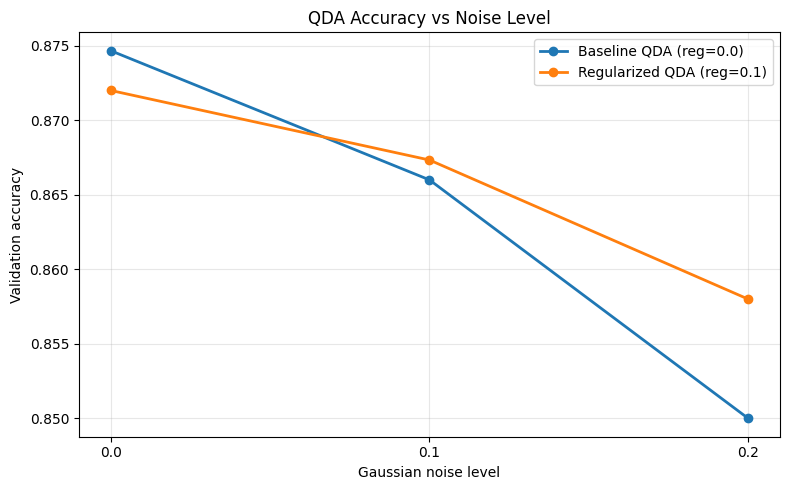

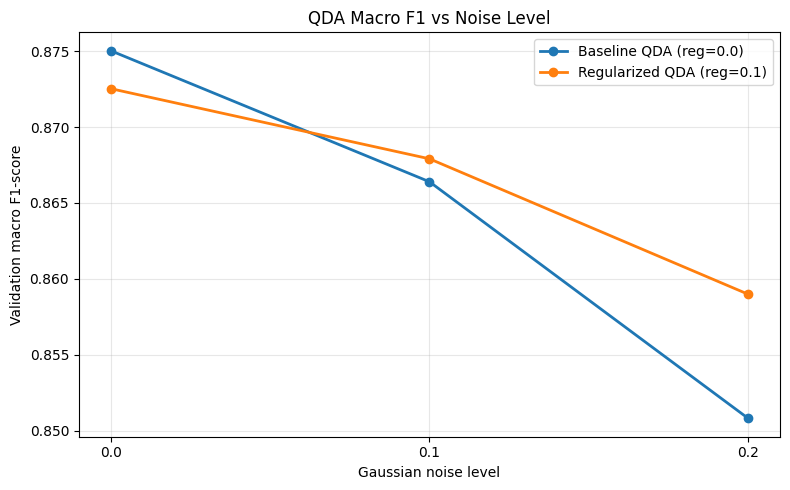

In [ ]:
# Step 7: Compare baseline and regularized QDA under noise

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

# Models already trained in previous steps
models = {
    "Baseline QDA (reg=0.0)": qda_model,
    "Regularized QDA (reg=0.1)": qda_reg_model
}

# Feature-wise noise scale calculated from training data
feature_std = X_train.std(axis=0).to_numpy()

# Fixed seed makes the experiment reproducible
rng = np.random.default_rng(42)

results = []

for noise_level in [0.0, 0.1, 0.2]:

    # Copy validation features; never modify the original data
    X_eval = X_val.to_numpy(dtype=float).copy()

    # Add Gaussian noise proportional to each feature's standard deviation
    if noise_level > 0:
        noise = rng.normal(
            loc=0.0,
            scale=noise_level * feature_std,
            size=X_eval.shape
        )
        X_eval += noise

    # Preserve column names to avoid sklearn feature-name warnings
    X_eval = pd.DataFrame(
        X_eval,
        columns=FEATURE_COLUMNS,
        index=X_val.index
    )

    # Evaluate both models on the exact same noisy data
    for model_name, model in models.items():
        predictions = model.predict(X_eval)

        results.append({
            "Model": model_name,
            "Noise level": noise_level,
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro F1": f1_score(
                y_val, predictions, average="macro"
            )
        })

# Create and display the results table
results_df = pd.DataFrame(results)

print("QDA performance under different noise levels:")
display(results_df.round(4))

# Plot 1: Accuracy versus noise
plt.figure(figsize=(8, 5))

for model_name in models:
    subset = results_df[results_df["Model"] == model_name]
    plt.plot(
        subset["Noise level"],
        subset["Accuracy"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.xlabel("Gaussian noise level")
plt.ylabel("Validation accuracy")
plt.title("QDA Accuracy vs Noise Level")
plt.xticks([0.0, 0.1, 0.2])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Plot 2: Macro F1 versus noise
plt.figure(figsize=(8, 5))

for model_name in models:
    subset = results_df[results_df["Model"] == model_name]
    plt.plot(
        subset["Noise level"],
        subset["Macro F1"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.xlabel("Gaussian noise level")
plt.ylabel("Validation macro F1-score")
plt.title("QDA Macro F1 vs Noise Level")
plt.xticks([0.0, 0.1, 0.2])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Conclusion: Comparing QDA Models Under Noise

Baseline QDA (`reg_param = 0.0`) performed best on clean validation data, achieving 87.47% accuracy and a macro F1-score of 0.8750. Regularized QDA (`reg_param = 0.1`) achieved slightly lower clean performance, with 87.20% accuracy and a macro F1-score of 0.8725.

Under Gaussian noise, regularized QDA performed better than baseline QDA. At noise levels 0.1 and 0.2, regularized QDA achieved accuracies of 86.73% and 85.80%, compared with 86.60% and 85.00% for baseline QDA. At noise level 0.2, its macro F1-score was 0.8590, compared with 0.8508 for baseline QDA.

These results suggest that mild covariance regularization may improve QDA's robustness to noisy features, although it slightly reduces clean-data performance. Since cross-validation selected `reg_param = 0.0` based on mean macro F1, the unregularized model remains the cross-validation winner. The regularized model is a useful alternative when robustness to feature noise is the priority.

### Step 8: Final QDA training and test predictions

The QDA experiments identified `reg_param = 0.0` as the best configuration based on five-fold stratified cross-validation, with a mean macro F1-score of 0.8895. Although mild regularization performed better under noisy validation conditions, the unregularized model achieved the best cross-validation result on the original training data.

For the final submission, we will refit the selected QDA configuration using all 7,500 cleaned training records. This allows the model to learn from both the previous training and validation records.

We will then predict the vehicle classes for the 2,500 test records and save the predictions in a separate CSV file. The test data will not be used for model selection, and existing submission files will not be overwritten.

In [ ]:
# Step 8: Train final QDA and create a separate submission file

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from pathlib import Path
import pandas as pd

# Use the best regularization parameter selected by cross-validation
final_qda_model = QuadraticDiscriminantAnalysis(
    reg_param=best_reg_param
)

# Fit on all cleaned training records
X_full = train_clean[FEATURE_COLUMNS]
y_full = train_clean["vehicle_class"]

final_qda_model.fit(X_full, y_full)

# Predict vehicle classes for the competition test dataset
X_test = test_df[FEATURE_COLUMNS].copy()
test_predictions = final_qda_model.predict(X_test)

# Create a separate results file; do not overwrite existing submissions
RESULTS_DIR = DATA_DIR.parent / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

submission_path = RESULTS_DIR / "qda_bayesian_classifier_submission.csv"

# Preserve the test ID column if it exists
if "vehicle_id" in test_df.columns:
    submission_df = pd.DataFrame({
        "vehicle_id": test_df["vehicle_id"],
        "vehicle_class": test_predictions
    })
else:
    submission_df = pd.DataFrame({
        "vehicle_class": test_predictions
    })

# Save the submission
submission_df.to_csv(submission_path, index=False)

# Verify the saved file
print("Final QDA model trained on:", len(X_full), "records")
print("Test predictions generated:", len(test_predictions))
print("Prediction class counts:")
print(pd.Series(test_predictions).value_counts().sort_index())
print("\nSubmission shape:", submission_df.shape)
print("Submission columns:", submission_df.columns.tolist())
print("Saved to:", submission_path)
print("\nFirst 5 submission rows:")
display(submission_df.head())

Final QDA model trained on: 7500 records
Test predictions generated: 2500
Prediction class counts:
0    847
1    830
2    823
Name: count, dtype: int64

Submission shape: (2500, 2)
Submission columns: ['vehicle_id', 'vehicle_class']
Saved to: /content/drive/MyDrive/MLproject/results/qda_bayesian_classifier_submission.csv

First 5 submission rows:


,vehicle_id,vehicle_class
0,10001,0
1,10002,0
2,10003,1
3,10004,2
4,10005,1


### Step 9: Train QDA with Gaussian noise augmentation

In the previous experiments, Gaussian noise was added only to the validation features. The QDA models were trained on clean data.

In this experiment, we will create a noisy copy of the training features by adding Gaussian noise with a standard deviation equal to 10% of each feature's standard deviation, calculated from the original training data.

The training labels will remain unchanged because noise augmentation modifies the input features, not the target classes. We will train a new QDA model on this augmented dataset and leave the original clean training data untouched.

Finally, we will compare this model with baseline QDA on clean validation data. We will evaluate noisy validation data in a subsequent step.

In [ ]:
# Step 9: Train QDA using Gaussian-noise-augmented features

import numpy as np
import pandas as pd
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score, f1_score

# Calculate noise scale from the original training features
feature_std = X_train.std(axis=0).to_numpy()

# Create a reproducible noisy copy of the training features
rng = np.random.default_rng(42)

training_noise = rng.normal(
    loc=0.0,
    scale=0.1 * feature_std,
    size=X_train.shape
)

X_train_noisy = pd.DataFrame(
    X_train.to_numpy(dtype=float) + training_noise,
    columns=FEATURE_COLUMNS,
    index=X_train.index
)

# Keep the original labels unchanged
y_train_noisy = y_train.copy()

# Train a new QDA model on the noisy features
qda_noisy_model = QuadraticDiscriminantAnalysis(reg_param=0.0)
qda_noisy_model.fit(X_train_noisy, y_train_noisy)

# Evaluate on clean validation data
y_val_noisy_model_pred = qda_noisy_model.predict(X_val)

# Compare with the original clean-trained QDA
comparison = pd.DataFrame([
    {
        "Model": "Clean-trained QDA",
        "Accuracy": accuracy_score(
            y_val, qda_model.predict(X_val)
        ),
        "Macro F1": f1_score(
            y_val, qda_model.predict(X_val), average="macro"
        )
    },
    {
        "Model": "Noise-trained QDA (0.1)",
        "Accuracy": accuracy_score(
            y_val, y_val_noisy_model_pred
        ),
        "Macro F1": f1_score(
            y_val, y_val_noisy_model_pred, average="macro"
        )
    }
])

print("Original training data:", X_train.shape)
print("Noise-augmented training data:", X_train_noisy.shape)
print("Training labels unchanged:", y_train_noisy.equals(y_train))

print("\nClean validation comparison:")
display(comparison.round(4))

Original training data: (6000, 20)
Noise-augmented training data: (6000, 20)
Training labels unchanged: True

Clean validation comparison:


,Model,Accuracy,Macro F1
0,Clean-trained QDA,0.8747,0.8750
1,Noise-trained QDA (0.1),0.8780,0.8784


### Conclusion: QDA with Gaussian Noise Augmentation

The baseline QDA model trained on clean features achieved a validation accuracy of 87.47% and a macro F1-score of 0.8750. After adding Gaussian noise at a relative level of 0.1 to the training features, the noise-augmented QDA model achieved 87.80% accuracy and a macro F1-score of 0.8784 on the same clean validation set.

This represents an improvement of 0.33 percentage points in accuracy and 0.0034 in macro F1-score. The result suggests that mild noise augmentation may improve generalization, although the improvement is modest and should be confirmed under noisy validation conditions.

The original cleaned dataset and training labels remained unchanged. Further evaluation will determine whether noise augmentation also improves robustness to noisy input features.

### Step 10: Evaluate noise-trained QDA under different noise levels

In the previous experiment, QDA trained on noise-augmented features achieved 87.80% validation accuracy and a macro F1-score of 0.8784 on clean validation data, slightly outperforming the clean-trained baseline.

Now, we will compare both models at Gaussian noise levels of 0.0, 0.1, and 0.2. At each level, both models will be evaluated on exactly the same validation features to ensure a fair comparison.

Noise will be added only to temporary copies of the validation features. The original training data, validation data, and labels will remain unchanged.

We will compare accuracy and macro F1-score using a results table and plots to determine whether noise augmentation improves robustness as well as clean-data performance.

Performance under different validation noise levels:


,Model,Noise level,Accuracy,Macro F1
0,Clean-trained QDA,0.0,0.8747,0.8750
1,Noise-trained QDA (0.1),0.0,0.8780,0.8784
2,Clean-trained QDA,0.1,0.8713,0.8717
3,Noise-trained QDA (0.1),0.1,0.8700,0.8705
4,Clean-trained QDA,0.2,0.8633,0.8640
5,Noise-trained QDA (0.1),0.2,0.8653,0.8661


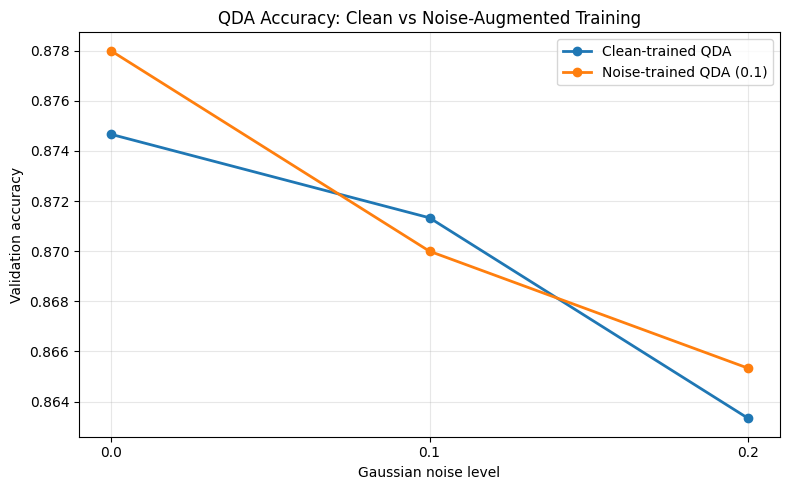

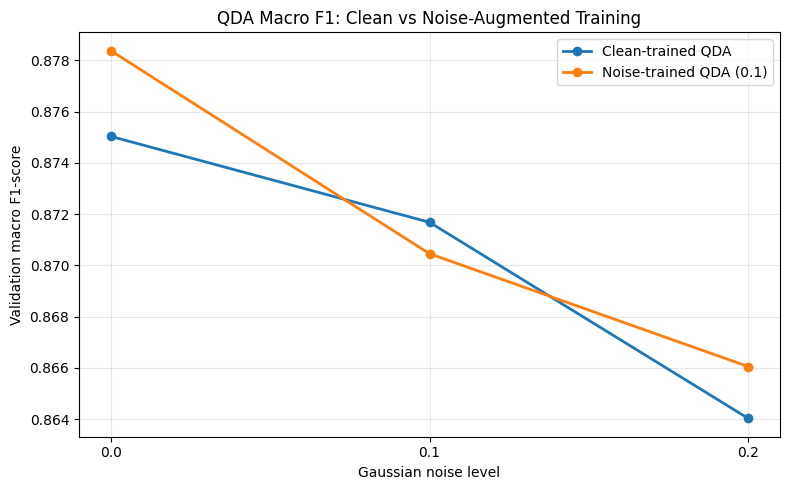

In [ ]:
# Step 10: Compare clean-trained and noise-trained QDA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

# Models trained in the previous steps
models = {
    "Clean-trained QDA": qda_model,
    "Noise-trained QDA (0.1)": qda_noisy_model
}

# Calculate feature-wise noise scales from training data
feature_std = X_train.std(axis=0).to_numpy()

# Fixed seed for reproducible evaluation
rng = np.random.default_rng(123)

results = []

for noise_level in [0.0, 0.1, 0.2]:

    # Make a fresh copy of the original validation features
    X_eval_array = X_val.to_numpy(dtype=float).copy()

    # Add Gaussian noise to the validation features
    if noise_level > 0:
        noise = rng.normal(
            loc=0.0,
            scale=noise_level * feature_std,
            size=X_eval_array.shape
        )
        X_eval_array += noise

    # Preserve feature names to avoid sklearn warnings
    X_eval = pd.DataFrame(
        X_eval_array,
        columns=FEATURE_COLUMNS,
        index=X_val.index
    )

    # Evaluate both models on the same validation features
    for model_name, model in models.items():
        predictions = model.predict(X_eval)

        results.append({
            "Model": model_name,
            "Noise level": noise_level,
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro F1": f1_score(
                y_val, predictions, average="macro"
            )
        })

# Display the comparison table
results_df = pd.DataFrame(results)
print("Performance under different validation noise levels:")
display(results_df.round(4))

# Plot 1: Accuracy comparison
plt.figure(figsize=(8, 5))

for model_name in models:
    subset = results_df[results_df["Model"] == model_name]
    plt.plot(
        subset["Noise level"],
        subset["Accuracy"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.xlabel("Gaussian noise level")
plt.ylabel("Validation accuracy")
plt.title("QDA Accuracy: Clean vs Noise-Augmented Training")
plt.xticks([0.0, 0.1, 0.2])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Plot 2: Macro F1 comparison
plt.figure(figsize=(8, 5))

for model_name in models:
    subset = results_df[results_df["Model"] == model_name]
    plt.plot(
        subset["Noise level"],
        subset["Macro F1"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.xlabel("Gaussian noise level")
plt.ylabel("Validation macro F1-score")
plt.title("QDA Macro F1: Clean vs Noise-Augmented Training")
plt.xticks([0.0, 0.1, 0.2])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Conclusion: Noise-Augmented QDA Under Different Noise Levels

The clean-trained QDA model achieved 87.47% accuracy and a macro F1-score of 0.8750 on clean validation data. QDA trained with Gaussian noise augmentation at level 0.1 improved these metrics to 87.80% and 0.8784, respectively.

When evaluated on noisy validation features, the noise-trained model did not outperform the clean-trained model at every noise level. At noise level 0.1, its accuracy was 87.00%, compared with 87.13% for clean-trained QDA. At noise level 0.2, noise-trained QDA achieved 86.53% accuracy, compared with 86.33% for clean-trained QDA.

Overall, noise augmentation produced a modest improvement on clean validation data and at the higher tested noise level, but its benefit was not consistent across all conditions. These results suggest that the effect of noise augmentation depends on the noise level and should be evaluated using both clean and noisy validation data.

### Step 12: Cross-validation for noise-augmented QDA

Previous experiments showed that QDA trained on Gaussian-noise-augmented features slightly outperformed clean-trained QDA on clean validation data. However, this comparison used only one train-validation split.

In this experiment, we will use five-fold stratified cross-validation to compare the two training strategies more reliably. Each fold will use the same training and validation indices for both models.

For the noise-augmented model, Gaussian noise will be added only to the fold's training features. The original class labels will remain unchanged. We will evaluate both models on clean validation features and on noisy copies with relative noise levels of 0.1 and 0.2.

We will report mean accuracy and macro F1-score across the five folds. The validation folds will not be used to calculate noise scales or train the models. This helps ensure a fair comparison without information leakage.

Five-fold cross-validation summary:


,Model,Validation noise,Mean_accuracy,Std_accuracy,Mean_macro_F1,Std_macro_F1
0,Clean-trained QDA,0.0,0.8848,0.0057,0.8855,0.0058
1,Clean-trained QDA,0.1,0.8785,0.0109,0.8792,0.0108
2,Clean-trained QDA,0.2,0.8736,0.0043,0.8746,0.0045
3,Noise-trained QDA (0.1),0.0,0.8864,0.0049,0.8870,0.0049
4,Noise-trained QDA (0.1),0.1,0.8804,0.0071,0.8810,0.0070
5,Noise-trained QDA (0.1),0.2,0.8788,0.0038,0.8797,0.0040


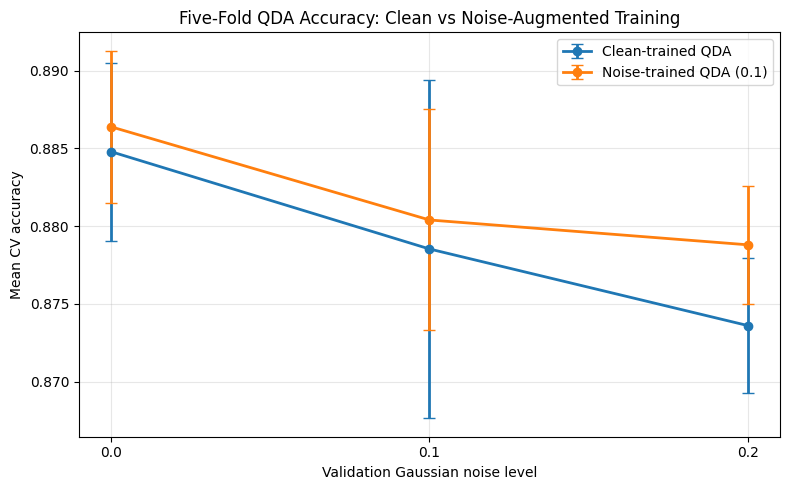

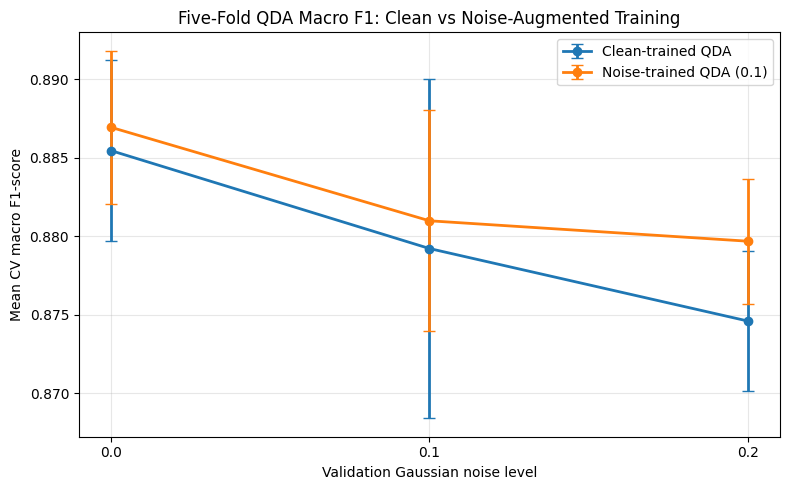

In [ ]:
# Step 12: Five-fold CV comparing clean-trained and noise-trained QDA

import numpy as np
import pandas as pd
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score

# Cross-validation configuration
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Store metrics for every fold, model, and evaluation noise level
cv_results = []

# Convert the full cleaned feature matrix to a numeric array
X_all = train_clean[FEATURE_COLUMNS].to_numpy(dtype=float)
y_all = train_clean["vehicle_class"].to_numpy()

for fold, (train_idx, val_idx) in enumerate(cv.split(X_all, y_all), start=1):

    # Split the data using this fold's indices
    X_fold_train = X_all[train_idx].copy()
    y_fold_train = y_all[train_idx]
    X_fold_val = X_all[val_idx].copy()
    y_fold_val = y_all[val_idx]

    # Calculate noise scales from this fold's training data only
    fold_std = X_fold_train.std(axis=0, ddof=1)

    # Create a reproducible noise generator for this fold
    rng = np.random.default_rng(1000 + fold)

    # Add relative Gaussian noise of 0.1 to training features
    training_noise = rng.normal(
        loc=0.0,
        scale=0.1 * fold_std,
        size=X_fold_train.shape
    )
    X_fold_train_noisy = X_fold_train + training_noise

    # Train both models on the same fold-training records
    clean_model = QuadraticDiscriminantAnalysis(reg_param=0.0)
    clean_model.fit(X_fold_train, y_fold_train)

    noisy_model = QuadraticDiscriminantAnalysis(reg_param=0.0)
    noisy_model.fit(X_fold_train_noisy, y_fold_train)

    models = {
        "Clean-trained QDA": clean_model,
        "Noise-trained QDA (0.1)": noisy_model
    }

    # Evaluate on clean validation data and noisy copies
    for eval_noise in [0.0, 0.1, 0.2]:

        X_eval = X_fold_val.copy()

        if eval_noise > 0:
            validation_noise = rng.normal(
                loc=0.0,
                scale=eval_noise * fold_std,
                size=X_eval.shape
            )
            X_eval += validation_noise

        for model_name, model in models.items():

            predictions = model.predict(X_eval)

            cv_results.append({
                "Fold": fold,
                "Model": model_name,
                "Validation noise": eval_noise,
                "Accuracy": accuracy_score(y_fold_val, predictions),
                "Macro F1": f1_score(
                    y_fold_val, predictions, average="macro"
                )
            })

# Store all fold-level results
cv_results_df = pd.DataFrame(cv_results)

# Summarize mean and standard deviation across folds
cv_summary = (
    cv_results_df
    .groupby(["Model", "Validation noise"])
    .agg(
        Mean_accuracy=("Accuracy", "mean"),
        Std_accuracy=("Accuracy", "std"),
        Mean_macro_F1=("Macro F1", "mean"),
        Std_macro_F1=("Macro F1", "std")
    )
    .reset_index()
)

print("Five-fold cross-validation summary:")
display(cv_summary.round(4))

# Plot 1: Mean accuracy across noise levels
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for model_name in cv_summary["Model"].unique():
    subset = cv_summary[cv_summary["Model"] == model_name]
    plt.errorbar(
        subset["Validation noise"],
        subset["Mean_accuracy"],
        yerr=subset["Std_accuracy"],
        marker="o",
        capsize=4,
        linewidth=2,
        label=model_name
    )

plt.xlabel("Validation Gaussian noise level")
plt.ylabel("Mean CV accuracy")
plt.title("Five-Fold QDA Accuracy: Clean vs Noise-Augmented Training")
plt.xticks([0.0, 0.1, 0.2])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Plot 2: Mean macro F1 across noise levels
plt.figure(figsize=(8, 5))

for model_name in cv_summary["Model"].unique():
    subset = cv_summary[cv_summary["Model"] == model_name]
    plt.errorbar(
        subset["Validation noise"],
        subset["Mean_macro_F1"],
        yerr=subset["Std_macro_F1"],
        marker="o",
        capsize=4,
        linewidth=2,
        label=model_name
    )

plt.xlabel("Validation Gaussian noise level")
plt.ylabel("Mean CV macro F1-score")
plt.title("Five-Fold QDA Macro F1: Clean vs Noise-Augmented Training")
plt.xticks([0.0, 0.1, 0.2])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Conclusion: Five-Fold Cross-Validation for Noise-Augmented QDA

Five-fold stratified cross-validation was used to compare clean-trained QDA with QDA trained using Gaussian noise augmentation at relative noise level 0.1. Both models used the same folds and were evaluated on clean validation features and noisy versions of those features.

Noise-augmented QDA achieved a mean macro F1-score of 0.8870 on clean validation folds, compared with 0.8855 for clean-trained QDA. At validation noise levels of 0.1 and 0.2, noise-augmented QDA achieved mean macro F1-scores of 0.8810 and 0.8797, compared with 0.8792 and 0.8746 for clean-trained QDA.

The noise-augmented model therefore achieved higher mean accuracy and macro F1-score at all three evaluation noise levels. The largest macro F1 improvement was observed at noise level 0.2.

These findings support noise augmentation as a promising training strategy for QDA in this experiment. However, the gains are modest, and cross-validation results alone do not establish statistical significance or guarantee a higher competition score. The noise-augmented model will be retained as a candidate for the final submission comparison.

### Objective: Generate the Noise-Augmented QDA Submission

In the previous experiment, noise-augmented QDA achieved better mean accuracy and macro F1-score than clean-trained QDA across all three validation noise levels in five-fold cross-validation.

In this step, we will:

1. Use all 7,500 cleaned training records.
2. Calculate each feature's standard deviation from the clean training data.
3. Create one noisy copy of the training features by adding Gaussian noise with a standard deviation equal to 10% of each feature's standard deviation.
4. Train QDA with `reg_param=0.0`, the value selected during regularization tuning.
5. Predict the vehicle classes for the 2,500 competition test records.
6. Save the predictions as a separate CSV file without overwriting our earlier submissions.

**Important:** Noise is added only to the training features. The original clean dataset remains unchanged, and the competition test features are not modified.

In [ ]:
# Step 13: Train final noise-augmented QDA and save predictions

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

# 1. Prepare all cleaned training features and labels.
X_all = train_clean[FEATURE_COLUMNS].copy()
y_all = train_clean["vehicle_class"].copy()

# 2. Calculate feature standard deviations using clean training data.
feature_std = X_all.std(axis=0, ddof=1)

# 3. Create one noisy copy of the training features.
rng = np.random.default_rng(42)
noise = rng.normal(
    loc=0.0,
    scale=0.1 * feature_std.to_numpy(),
    size=X_all.shape
)

X_all_noisy = X_all + noise

# Preserve feature names for scikit-learn.
X_all_noisy = pd.DataFrame(
    X_all_noisy,
    columns=FEATURE_COLUMNS,
    index=X_all.index
)

# 4. Train QDA on the noise-augmented training data.
final_qda_noise = QuadraticDiscriminantAnalysis(reg_param=0.0)
final_qda_noise.fit(X_all_noisy, y_all)

# 5. Predict on the original, unmodified test features.
test_predictions = final_qda_noise.predict(X_test)

# 6. Create the submission with the expected column names.
submission = pd.DataFrame({
    "vehicle_id": test_df["vehicle_id"],
    "vehicle_class": test_predictions
})

# 7. Save separately so earlier submissions are preserved.
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
submission_path = RESULTS_DIR / "qda_noise_augmented_0.1_submission.csv"
submission.to_csv(submission_path, index=False)

# 8. Verify the saved file and prediction distribution.
print("Submission saved to:", submission_path)
print("Submission shape:", submission.shape)
print("\nFirst five rows:")
display(submission.head())

print("\nPredicted class counts:")
display(submission["vehicle_class"].value_counts().sort_index())

Submission saved to: /content/drive/MyDrive/MLproject/results/qda_noise_augmented_0.1_submission.csv
Submission shape: (2500, 2)

First five rows:


,vehicle_id,vehicle_class
0,10001,0
1,10002,0
2,10003,1
3,10004,2
4,10005,1



Predicted class counts:


,count
vehicle_class,
0,852
1,823
2,825
